# Alzheimer's Disease — End-to-End ML Project
**Preprocessing & EDA → Baseline models (4 team members) → Hyperparameter tuning (RF, HistGB, XGBoost) → Final comparison & best model**

| Part | Contents |
|---|---|
| 1–6 | Data loading, audit, cleaning, EDA, ML-ready split & scaling, key findings |
| 7 | Shared evaluation helpers |
| 8 | Baselines — Random Forest + SVM (Dhruti) |
| 9 | Baselines — KNN + XGBoost (Akshatha) |
| 10 | Baselines — HistGradientBoosting + GradientBoosting (Ankit) |
| 11 | Baselines — Logistic Regression + Naive Bayes (Aarti) |
| 12 | All-baseline comparison |
| 13 | Hyperparameter tuning — Random Forest, HistGradientBoosting, XGBoost |
| 14 | Tuned-model comparison: metrics, confusion matrices, charts |
| 15 | Best model |

## 1. Setup & data loading

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# ---------------- Configuration ----------------
DATA_PATH    = "alzheimers_disease_data.csv"   # change if your file lives elsewhere
OUTPUT_DIR   = "cleaned_output"
RANDOM_STATE = 42
TEST_SIZE    = 0.20
CAP_OUTLIERS = False      # True -> winsorise outliers using 1.5*IQR fences (see section 3)
ADD_ENGINEERED_FEATURES = True
# -----------------------------------------------
os.makedirs(OUTPUT_DIR, exist_ok=True)

PALETTE = {0: "#4C78A8", 1: "#E4572E"}          # 0 = No Alzheimer's, 1 = Alzheimer's
DIAG_LABELS = {0: "No Alzheimer's", 1: "Alzheimer's"}

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Loaded 2,149 rows x 35 columns


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,CardiovascularDisease,Diabetes,Depression,HeadInjury,Hypertension,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.928,0,13.297,6.327,1.347,9.026,0,0,1,1,0,0,142,72,242.367,56.151,33.683,162.189,21.464,6.519,0,0,1.726,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.828,0,4.543,7.620,0.519,7.151,0,0,0,0,0,0,115,64,231.163,193.408,79.028,294.631,20.613,7.119,0,0,2.592,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.796,0,19.555,7.845,1.826,9.674,1,0,0,0,0,0,99,116,284.182,153.323,69.772,83.638,7.356,5.895,0,0,7.120,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.801,1,12.209,8.428,7.436,8.393,0,0,0,0,0,0,118,115,159.582,65.367,68.457,277.577,13.991,8.965,0,1,6.481,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.717,0,18.454,6.310,0.795,5.597,0,0,0,0,0,0,94,117,237.602,92.870,56.874,291.199,13.518,6.045,0,0,0.015,0,0,1,1,0,0,XXXConfid


### Column groups
Grouping the columns by type drives every later step (which plots, which tests, which scaler).

In [2]:
TARGET = "Diagnosis"
ID_COLS = ["PatientID"]                  # identifier -> no predictive value
CONSTANT_LIKE = ["DoctorInCharge"]       # single value for every row (verified in audit below)

CONTINUOUS = ["Age", "BMI", "AlcoholConsumption", "PhysicalActivity", "DietQuality", "SleepQuality",
              "SystolicBP", "DiastolicBP", "CholesterolTotal", "CholesterolLDL", "CholesterolHDL",
              "CholesterolTriglycerides", "MMSE", "FunctionalAssessment", "ADL"]

BINARY = ["Gender", "Smoking", "FamilyHistoryAlzheimers", "CardiovascularDisease", "Diabetes",
          "Depression", "HeadInjury", "Hypertension", "MemoryComplaints", "BehavioralProblems",
          "Confusion", "Disorientation", "PersonalityChanges", "DifficultyCompletingTasks", "Forgetfulness"]

NOMINAL = ["Ethnicity"]                  # 0 Caucasian, 1 African American, 2 Asian, 3 Other
ORDINAL = ["EducationLevel"]             # 0 None, 1 High School, 2 Bachelor's, 3 Higher

LABELS = {
    "Gender": {0: "Male", 1: "Female"},
    "Ethnicity": {0: "Caucasian", 1: "African American", 2: "Asian", 3: "Other"},
    "EducationLevel": {0: "None", 1: "High School", 2: "Bachelor's", 3: "Higher"},
}

covered = set(ID_COLS + CONSTANT_LIKE + CONTINUOUS + BINARY + NOMINAL + ORDINAL + [TARGET])
print("Columns not assigned to a group:", set(df_raw.columns) - covered or "none  (all 35 covered)")
print({"continuous": len(CONTINUOUS), "binary": len(BINARY), "nominal": len(NOMINAL),
       "ordinal": len(ORDINAL), "id": len(ID_COLS), "constant": len(CONSTANT_LIKE), "target": 1})

Columns not assigned to a group: none  (all 35 covered)
{'continuous': 15, 'binary': 15, 'nominal': 1, 'ordinal': 1, 'id': 1, 'constant': 1, 'target': 1}


## 2. Data audit

In [3]:
print("Shape:", df_raw.shape)
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                      "non_null": df_raw.notna().sum(),
                      "n_unique": df_raw.nunique()}))

Shape: (2149, 35)


,dtype,non_null,n_unique
PatientID,int64,2149,2149
Age,int64,2149,31
Gender,int64,2149,2
Ethnicity,int64,2149,4
EducationLevel,int64,2149,4
BMI,float64,2149,2149
Smoking,int64,2149,2
AlcoholConsumption,float64,2149,2149
PhysicalActivity,float64,2149,2149
DietQuality,float64,2149,2149


In [4]:
display(df_raw[CONTINUOUS].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,"2,149.000",74.909,8.990,60.000,67.000,75.000,83.000,90.000
BMI,"2,149.000",27.656,7.217,15.009,21.611,27.824,33.870,39.993
AlcoholConsumption,"2,149.000",10.039,5.758,0.002,5.140,9.934,15.158,19.989
PhysicalActivity,"2,149.000",4.920,2.857,0.004,2.571,4.766,7.428,9.987
DietQuality,"2,149.000",4.993,2.909,0.009,2.458,5.076,7.559,9.998
SleepQuality,"2,149.000",7.051,1.764,4.003,5.483,7.116,8.563,10.000
SystolicBP,"2,149.000",134.265,25.949,90.000,112.000,134.000,157.000,179.000
DiastolicBP,"2,149.000",89.848,17.592,60.000,74.000,91.000,105.000,119.000
CholesterolTotal,"2,149.000",225.198,42.542,150.093,190.253,225.086,262.032,299.993
CholesterolLDL,"2,149.000",124.336,43.367,50.231,87.196,123.343,161.734,199.966


In [5]:
# ---- Missing values, duplicates, constant columns, identifier uniqueness ----
missing = df_raw.isna().sum()
print("Total missing cells      :", int(missing.sum()))
print("Fully duplicated rows    :", int(df_raw.duplicated().sum()))
print("Duplicate PatientIDs     :", int(df_raw["PatientID"].duplicated().sum()))
const_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print("Constant columns         :", const_cols)
print("DoctorInCharge values    :", df_raw["DoctorInCharge"].unique())

# Unexpected values in the coded categorical columns
for c in BINARY + NOMINAL + ORDINAL + [TARGET]:
    print(f"{c:28s} -> {sorted(df_raw[c].unique())}")

Total missing cells      : 0
Fully duplicated rows    : 0
Duplicate PatientIDs     : 0
Constant columns         : ['DoctorInCharge']
DoctorInCharge values    : ['XXXConfid']
Gender                       -> [np.int64(0), np.int64(1)]
Smoking                      -> [np.int64(0), np.int64(1)]
FamilyHistoryAlzheimers      -> [np.int64(0), np.int64(1)]
CardiovascularDisease        -> [np.int64(0), np.int64(1)]
Diabetes                     -> [np.int64(0), np.int64(1)]
Depression                   -> [np.int64(0), np.int64(1)]
HeadInjury                   -> [np.int64(0), np.int64(1)]
Hypertension                 -> [np.int64(0), np.int64(1)]
MemoryComplaints             -> [np.int64(0), np.int64(1)]
BehavioralProblems           -> [np.int64(0), np.int64(1)]
Confusion                    -> [np.int64(0), np.int64(1)]
Disorientation               -> [np.int64(0), np.int64(1)]
PersonalityChanges           -> [np.int64(0), np.int64(1)]
DifficultyCompletingTasks    -> [np.int64(0), np.int64(1)]


In [6]:
# ---- Plausible-range validation (clinical / scale limits) ----
VALID_RANGES = {
    "Age": (60, 90), "BMI": (15, 40), "AlcoholConsumption": (0, 20), "PhysicalActivity": (0, 10),
    "DietQuality": (0, 10), "SleepQuality": (4, 10), "SystolicBP": (90, 180), "DiastolicBP": (60, 120),
    "CholesterolTotal": (150, 300), "CholesterolLDL": (50, 200), "CholesterolHDL": (20, 100),
    "CholesterolTriglycerides": (50, 400), "MMSE": (0, 30), "FunctionalAssessment": (0, 10), "ADL": (0, 10),
}
rows = []
for c, (lo, hi) in VALID_RANGES.items():
    bad = int(((df_raw[c] < lo) | (df_raw[c] > hi)).sum())
    rows.append([c, lo, hi, df_raw[c].min(), df_raw[c].max(), bad])
range_report = pd.DataFrame(rows, columns=["feature", "valid_min", "valid_max", "observed_min", "observed_max", "n_out_of_range"])
display(range_report)
print("Total out-of-range values:", range_report["n_out_of_range"].sum())

,feature,valid_min,valid_max,observed_min,observed_max,n_out_of_range
0,Age,60,90,60.000,90.000,0
1,BMI,15,40,15.009,39.993,0
2,AlcoholConsumption,0,20,0.002,19.989,0
3,PhysicalActivity,0,10,0.004,9.987,0
4,DietQuality,0,10,0.009,9.998,0
5,SleepQuality,4,10,4.003,10.000,0
6,SystolicBP,90,180,90.000,179.000,0
7,DiastolicBP,60,120,60.000,119.000,0
8,CholesterolTotal,150,300,150.093,299.993,0
9,CholesterolLDL,50,200,50.231,199.966,0


Total out-of-range values: 0


,n_outliers,pct
Age,0,0.000
BMI,0,0.000
AlcoholConsumption,0,0.000
PhysicalActivity,0,0.000
DietQuality,0,0.000
SleepQuality,0,0.000
SystolicBP,0,0.000
DiastolicBP,0,0.000
CholesterolTotal,0,0.000
CholesterolLDL,0,0.000


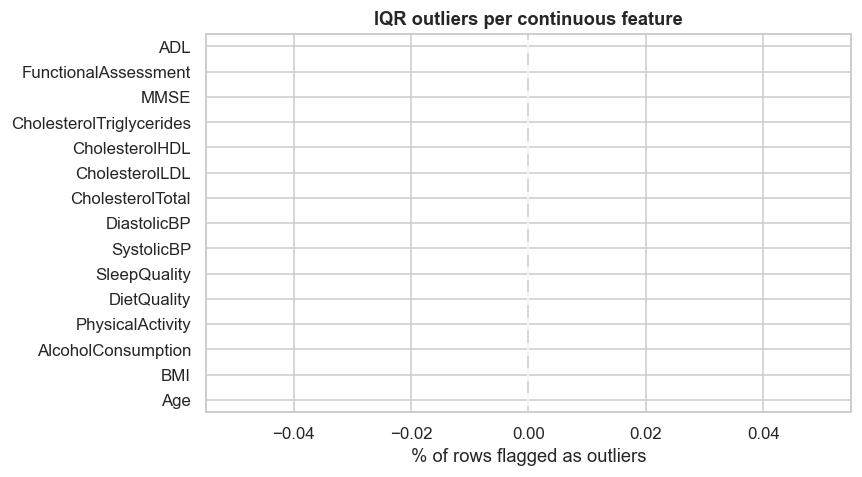

In [7]:
# ---- Statistical outliers (1.5 x IQR rule) ----
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({"n_outliers": [iqr_outliers(df_raw[c]) for c in CONTINUOUS]}, index=CONTINUOUS)
out["pct"] = 100 * out["n_outliers"] / len(df_raw)
display(out.sort_values("n_outliers", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
out["pct"].sort_values().plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("% of rows flagged as outliers"); ax.set_title("IQR outliers per continuous feature")
plt.tight_layout(); plt.show()

**Audit takeaways**
- No missing values and no duplicate rows, so the cleaning work is mostly *structural* (dropping non-informative columns, typing, feature engineering, encoding, scaling).
- `PatientID` is a unique identifier and `DoctorInCharge` holds a single value for all rows — neither carries predictive information, so both are dropped.
- All values fall inside plausible clinical ranges and no feature has IQR outliers, so nothing is removed or capped. Outlier capping is therefore **off by default** (`CAP_OUTLIERS = False`) but available if you swap in other data.
- The imputation and range-check code below is kept in the pipeline anyway, so the notebook still works if you swap in a different/dirtier version of the data.

## 3. Data preprocessing

In [8]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
log = []   # preprocessing log

# Step 1 - remove duplicate rows
n0 = len(df); df = df.drop_duplicates().reset_index(drop=True)
log.append(f"1. Removed duplicate rows: {n0 - len(df)}")

# Step 2 - values outside valid range -> NaN (then imputed in step 3)
n_bad = 0
for c, (lo, hi) in VALID_RANGES.items():
    mask = (df[c] < lo) | (df[c] > hi)
    n_bad += int(mask.sum()); df.loc[mask, c] = np.nan
log.append(f"2. Out-of-range values set to NaN: {n_bad}")

# Step 3 - impute missing values (median for numeric, mode for categorical/binary)
n_missing = int(df.isna().sum().sum())
for c in CONTINUOUS:
    if df[c].isna().any(): df[c] = df[c].fillna(df[c].median())
for c in BINARY + NOMINAL + ORDINAL + [TARGET]:
    if df[c].isna().any(): df[c] = df[c].fillna(df[c].mode()[0])
log.append(f"3. Missing values imputed: {n_missing}")

# Step 4 - drop identifier + constant columns
drop_cols = ID_COLS + [c for c in CONSTANT_LIKE if c in df.columns]
df = df.drop(columns=drop_cols)
log.append(f"4. Dropped non-informative columns: {drop_cols}")

# Step 5 - enforce data types
for c in BINARY + NOMINAL + ORDINAL + [TARGET]:
    df[c] = df[c].astype("int8")
log.append("5. Binary / categorical / target columns cast to int8")

# Step 6 - (optional) cap statistical outliers with 1.5*IQR fences
if CAP_OUTLIERS:
    for c in CONTINUOUS:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        df[c] = df[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    log.append("6. Outliers winsorised with 1.5*IQR fences")
else:
    log.append("6. Outlier capping skipped (all values are within valid clinical ranges)")

print("\n".join(log))

1. Removed duplicate rows: 0
2. Out-of-range values set to NaN: 0
3. Missing values imputed: 0
4. Dropped non-informative columns: ['PatientID', 'DoctorInCharge']
5. Binary / categorical / target columns cast to int8
6. Outlier capping skipped (all values are within valid clinical ranges)


### Feature engineering
Clinically motivated features that summarise several raw columns. They are added to the cleaned dataset (and can be switched off with `ADD_ENGINEERED_FEATURES`).

| Feature | Definition |
|---|---|
| `PulsePressure` | Systolic − Diastolic BP |
| `CholesterolRatio` | Total cholesterol ÷ HDL |
| `SymptomCount` | Sum of the 7 symptom flags (memory complaints, behavioral problems, confusion, disorientation, personality changes, difficulty completing tasks, forgetfulness) |
| `ComorbidityCount` | Sum of the 5 medical-history flags (cardiovascular disease, diabetes, depression, head injury, hypertension) |
| `AgeGroup` | 60-69, 70-79, 80-90 (EDA helper) |
| `BMICategory` | Underweight / Normal / Overweight / Obese (EDA helper) |

In [9]:
SYMPTOMS = ["MemoryComplaints", "BehavioralProblems", "Confusion", "Disorientation",
            "PersonalityChanges", "DifficultyCompletingTasks", "Forgetfulness"]
COMORBID = ["CardiovascularDisease", "Diabetes", "Depression", "HeadInjury", "Hypertension"]

ENGINEERED_NUM = []
if ADD_ENGINEERED_FEATURES:
    df["PulsePressure"]    = df["SystolicBP"] - df["DiastolicBP"]
    df["CholesterolRatio"] = df["CholesterolTotal"] / df["CholesterolHDL"]
    df["SymptomCount"]     = df[SYMPTOMS].sum(axis=1).astype("int8")
    df["ComorbidityCount"] = df[COMORBID].sum(axis=1).astype("int8")
    df["AgeGroup"] = pd.cut(df["Age"], bins=[59, 69, 79, 90], labels=["60-69", "70-79", "80-90"])
    df["BMICategory"] = pd.cut(df["BMI"], bins=[0, 18.5, 25, 30, 100],
                               labels=["Underweight", "Normal", "Overweight", "Obese"])
    ENGINEERED_NUM = ["PulsePressure", "CholesterolRatio"]

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
df.head()

Cleaned dataset shape: (2149, 39)
Remaining missing values: 0


,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,CardiovascularDisease,Diabetes,Depression,HeadInjury,Hypertension,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,PulsePressure,CholesterolRatio,SymptomCount,ComorbidityCount,AgeGroup,BMICategory
0,73.000,0,0,2,22.928,0,13.297,6.327,1.347,9.026,0,0,1,1,0,0,142.000,72.000,242.367,56.151,33.683,162.189,21.464,6.519,0,0,1.726,0,0,0,1,0,0,70.000,7.196,1,2,70-79,Normal
1,89.000,0,0,0,26.828,0,4.543,7.620,0.519,7.151,0,0,0,0,0,0,115.000,64.000,231.163,193.408,79.028,294.631,20.613,7.119,0,0,2.592,0,0,0,0,1,0,51.000,2.925,1,0,80-90,Overweight
2,73.000,0,3,1,17.796,0,19.555,7.845,1.826,9.674,1,0,0,0,0,0,99.000,116.000,284.182,153.323,69.772,83.638,7.356,5.895,0,0,7.120,0,1,0,1,0,0,-17.000,4.073,2,0,70-79,Underweight
3,74.000,1,0,1,33.801,1,12.209,8.428,7.436,8.393,0,0,0,0,0,0,118.000,115.000,159.582,65.367,68.457,277.577,13.991,8.965,0,1,6.481,0,0,0,0,0,0,3.000,2.331,1,0,70-79,Obese
4,89.000,0,0,0,20.717,0,18.454,6.310,0.795,5.597,0,0,0,0,0,0,94.000,117.000,237.602,92.870,56.874,291.199,13.518,6.045,0,0,0.015,0,0,1,1,0,0,-23.000,4.178,2,0,80-90,Normal


### Export the cleaned dataset

In [10]:
# Cleaned data (original numeric codes kept, non-informative columns dropped, engineered features added)
cleaned_path = os.path.join(OUTPUT_DIR, "alzheimers_cleaned.csv")
df.to_csv(cleaned_path, index=False)

# Human-readable version (codes replaced by labels) - handy for reports / BI tools
df_labeled = df.copy()
for col, mapping in LABELS.items():
    df_labeled[col] = df_labeled[col].map(mapping)
df_labeled[TARGET] = df_labeled[TARGET].map(DIAG_LABELS)
labeled_path = os.path.join(OUTPUT_DIR, "alzheimers_cleaned_labeled.csv")
df_labeled.to_csv(labeled_path, index=False)

print("Saved:", cleaned_path, df.shape)
print("Saved:", labeled_path, df_labeled.shape)

Saved: cleaned_output\alzheimers_cleaned.csv (2149, 39)
Saved: cleaned_output\alzheimers_cleaned_labeled.csv (2149, 39)


## 4. Exploratory data analysis
All EDA below uses the cleaned dataset `df`.
### 4.1 Target distribution

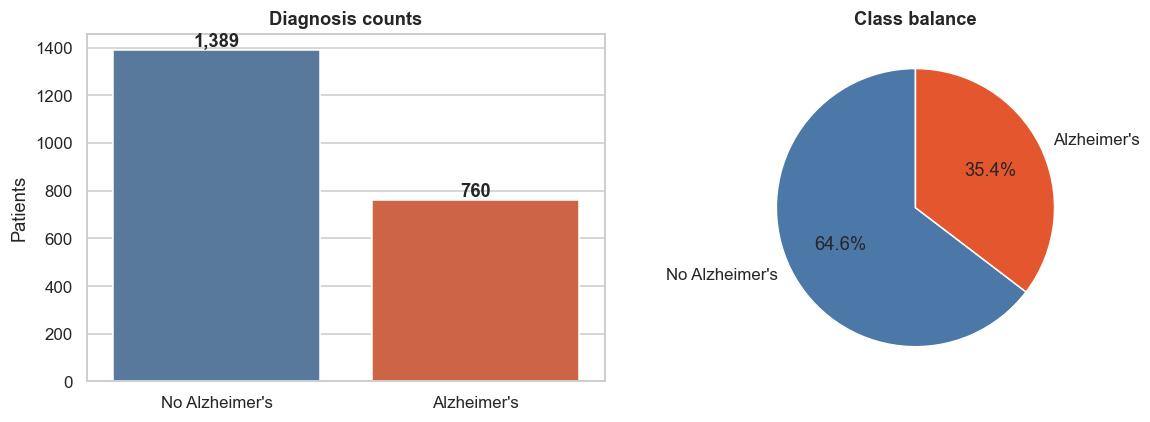

Imbalance ratio (majority:minority) = 1.83 : 1


In [11]:
counts = df[TARGET].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=[DIAG_LABELS[i] for i in counts.index], y=counts.values, palette=[PALETTE[i] for i in counts.index], ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, f"{v:,}", ha="center", fontweight="bold")
axes[0].set_title("Diagnosis counts"); axes[0].set_ylabel("Patients")
axes[1].pie(counts.values, labels=[DIAG_LABELS[i] for i in counts.index], autopct="%1.1f%%",
            colors=[PALETTE[i] for i in counts.index], startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Class balance")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (majority:minority) = {counts.max() / counts.min():.2f} : 1")

### 4.2 Demographics

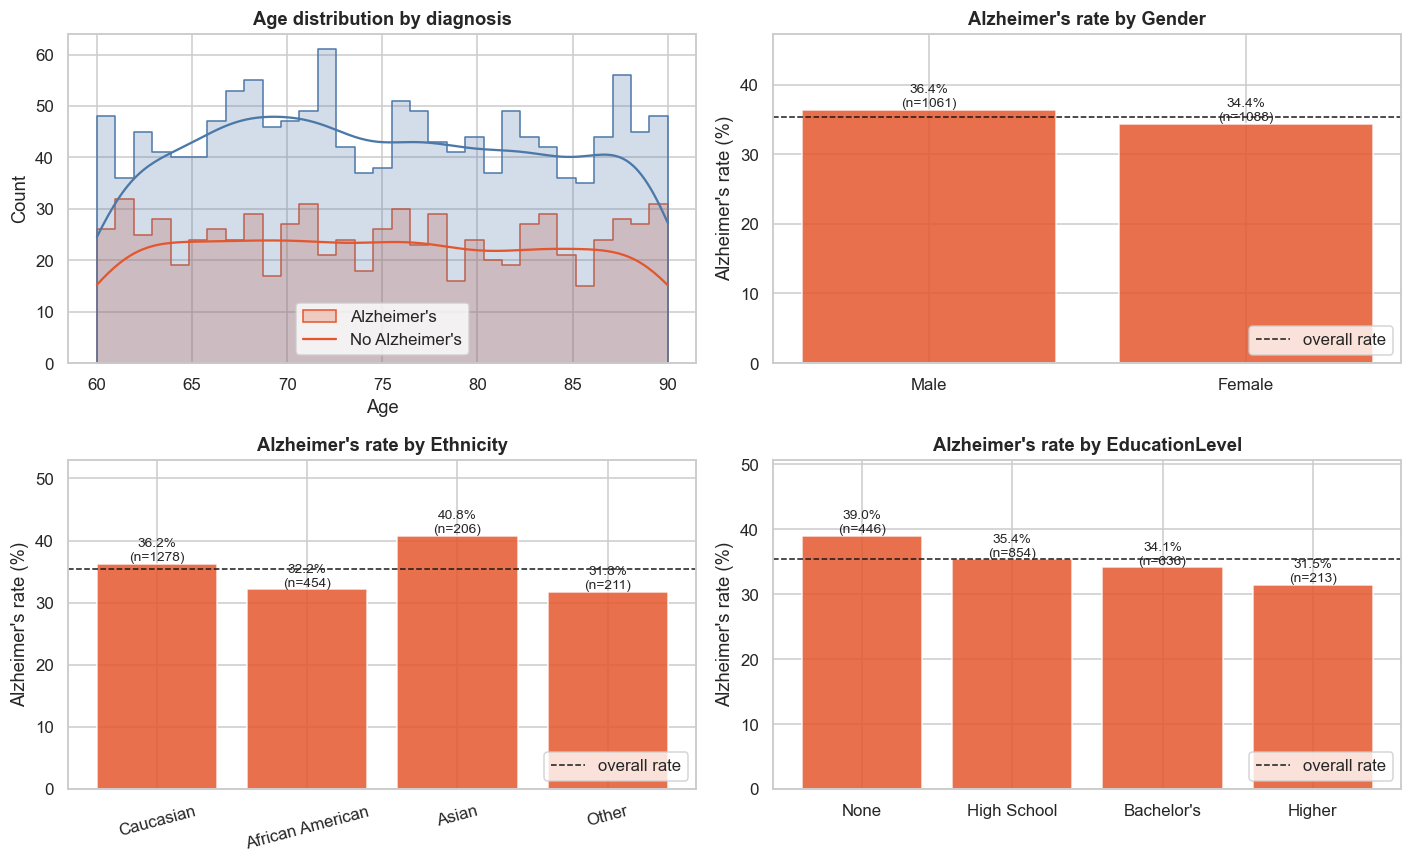

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(data=df, x="Age", hue=TARGET, palette=PALETTE, bins=31, kde=True, element="step", ax=axes[0, 0])
axes[0, 0].set_title("Age distribution by diagnosis")
axes[0, 0].legend(labels=[DIAG_LABELS[1], DIAG_LABELS[0]], title="")

for ax, col in zip(axes.flat[1:], ["Gender", "Ethnicity", "EducationLevel"]):
    rate = df.groupby(col)[TARGET].mean().mul(100)
    n = df[col].value_counts().sort_index()
    names = [LABELS[col][i] for i in rate.index]
    bars = ax.bar(names, rate.values, color="#E4572E", alpha=.85)
    ax.axhline(df[TARGET].mean() * 100, color="k", ls="--", lw=1, label="overall rate")
    for b, v, k in zip(bars, rate.values, n.reindex(rate.index).values):
        ax.text(b.get_x() + b.get_width() / 2, v + .5, f"{v:.1f}%\n(n={k})", ha="center", fontsize=9)
    ax.set_ylim(0, rate.max() * 1.3); ax.set_ylabel("Alzheimer's rate (%)")
    ax.set_title(f"Alzheimer's rate by {col}"); ax.legend(loc="lower right")
    if col == "Ethnicity": ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

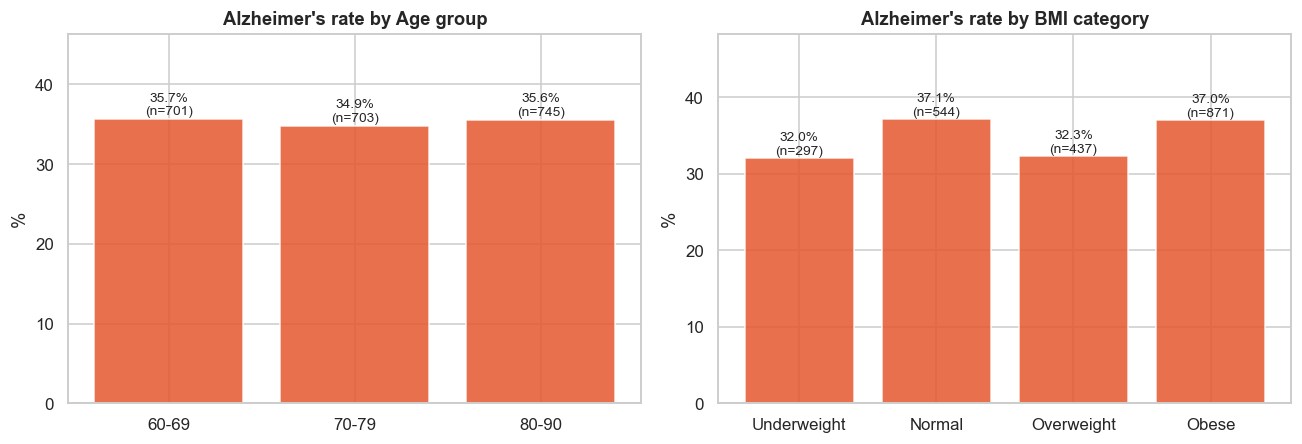

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title in zip(axes, ["AgeGroup", "BMICategory"], ["Age group", "BMI category"]):
    if col not in df: continue
    rate = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    ax.bar(rate.index.astype(str), rate["mean"] * 100, color="#E4572E", alpha=.85)
    for i, (m, s) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, m * 100 + .5, f"{m*100:.1f}%\n(n={s})", ha="center", fontsize=9)
    ax.set_ylim(0, rate["mean"].max() * 130); ax.set_title(f"Alzheimer's rate by {title}"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

### 4.3 Distributions of continuous features

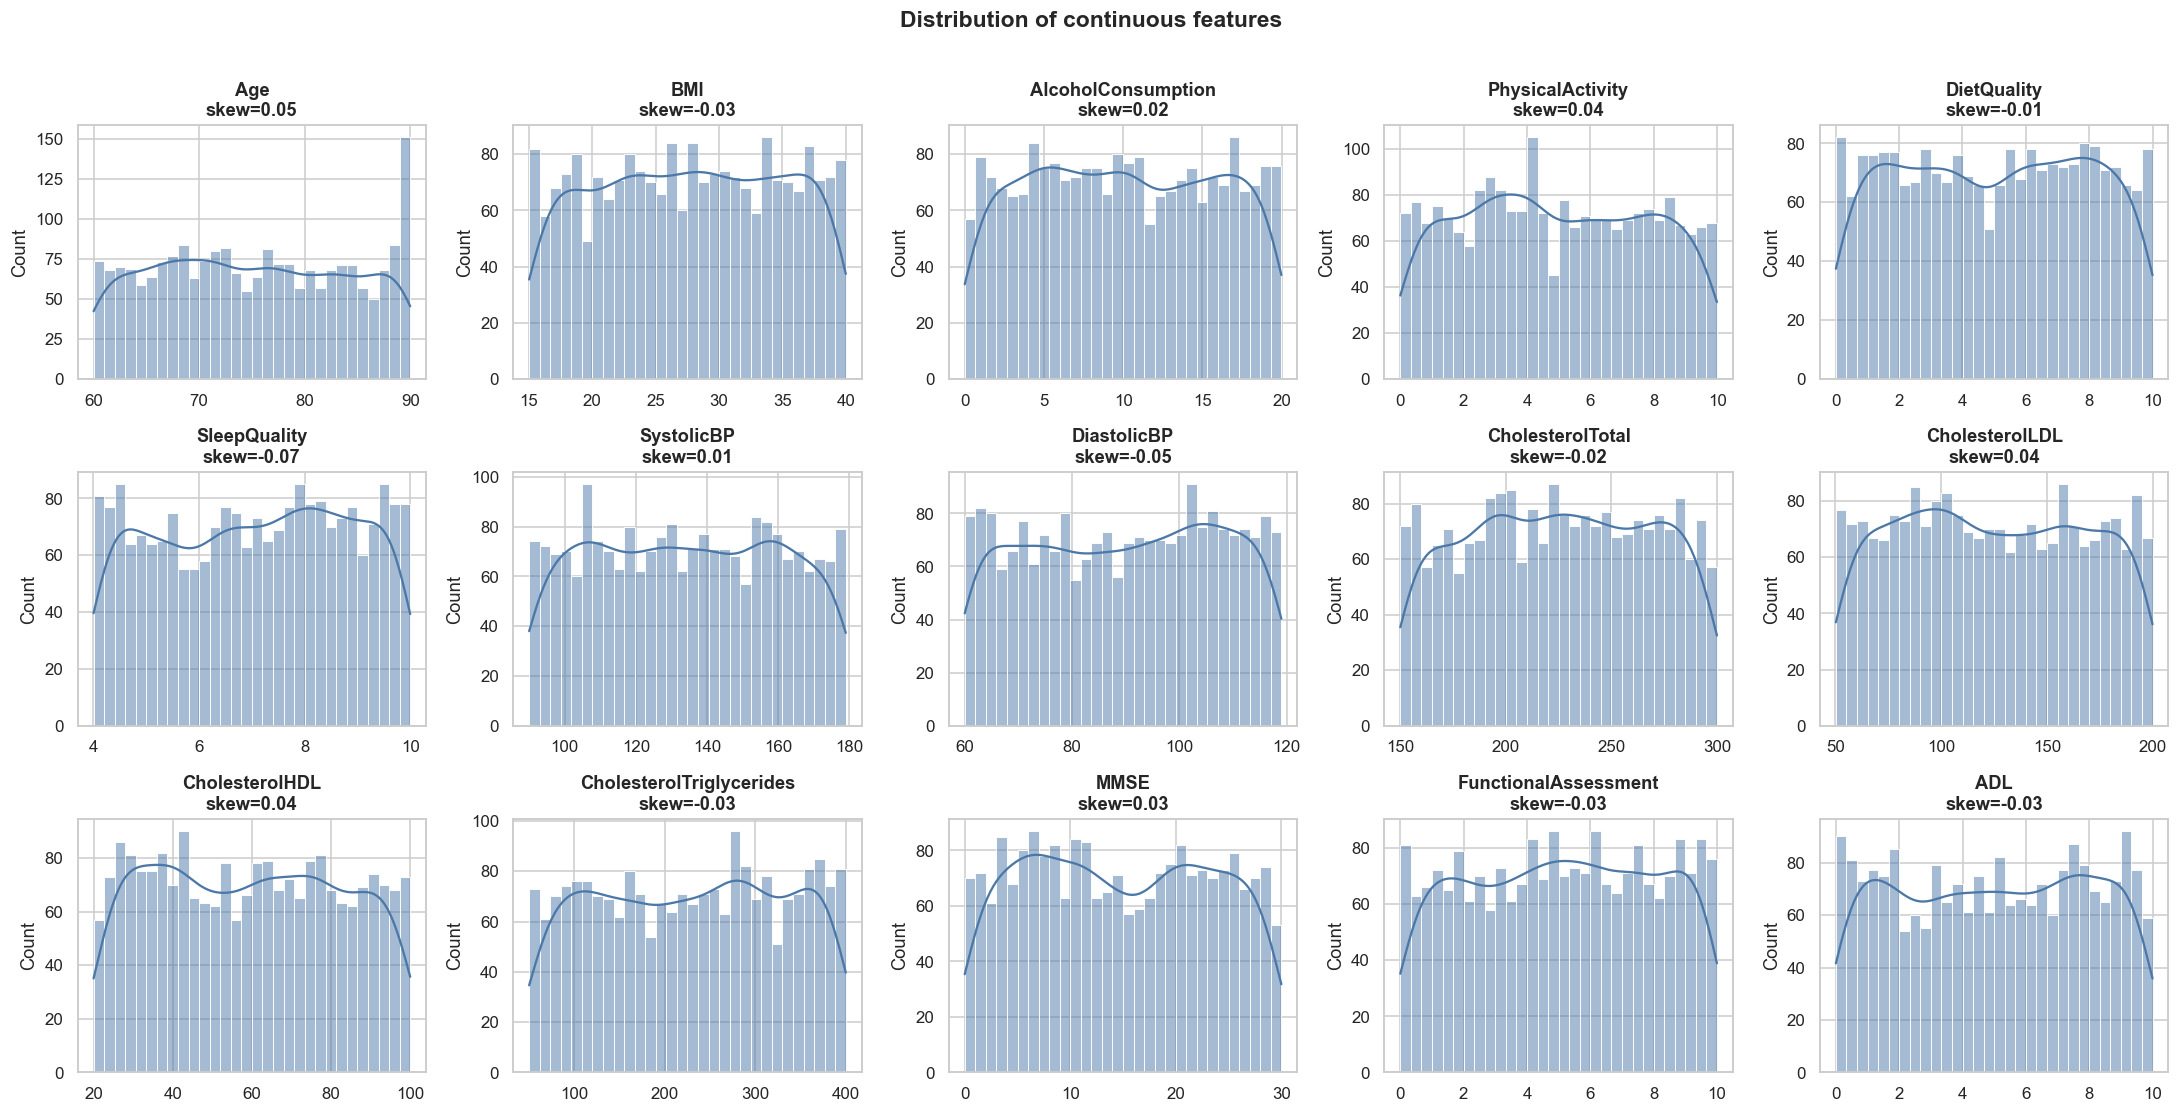

In [14]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, c in zip(axes.flat, CONTINUOUS):
    sns.histplot(df[c], kde=True, bins=30, color="#4C78A8", ax=ax)
    ax.set_title(f"{c}\nskew={df[c].skew():.2f}"); ax.set_xlabel("")
plt.suptitle("Distribution of continuous features", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 4.4 Continuous features vs. diagnosis

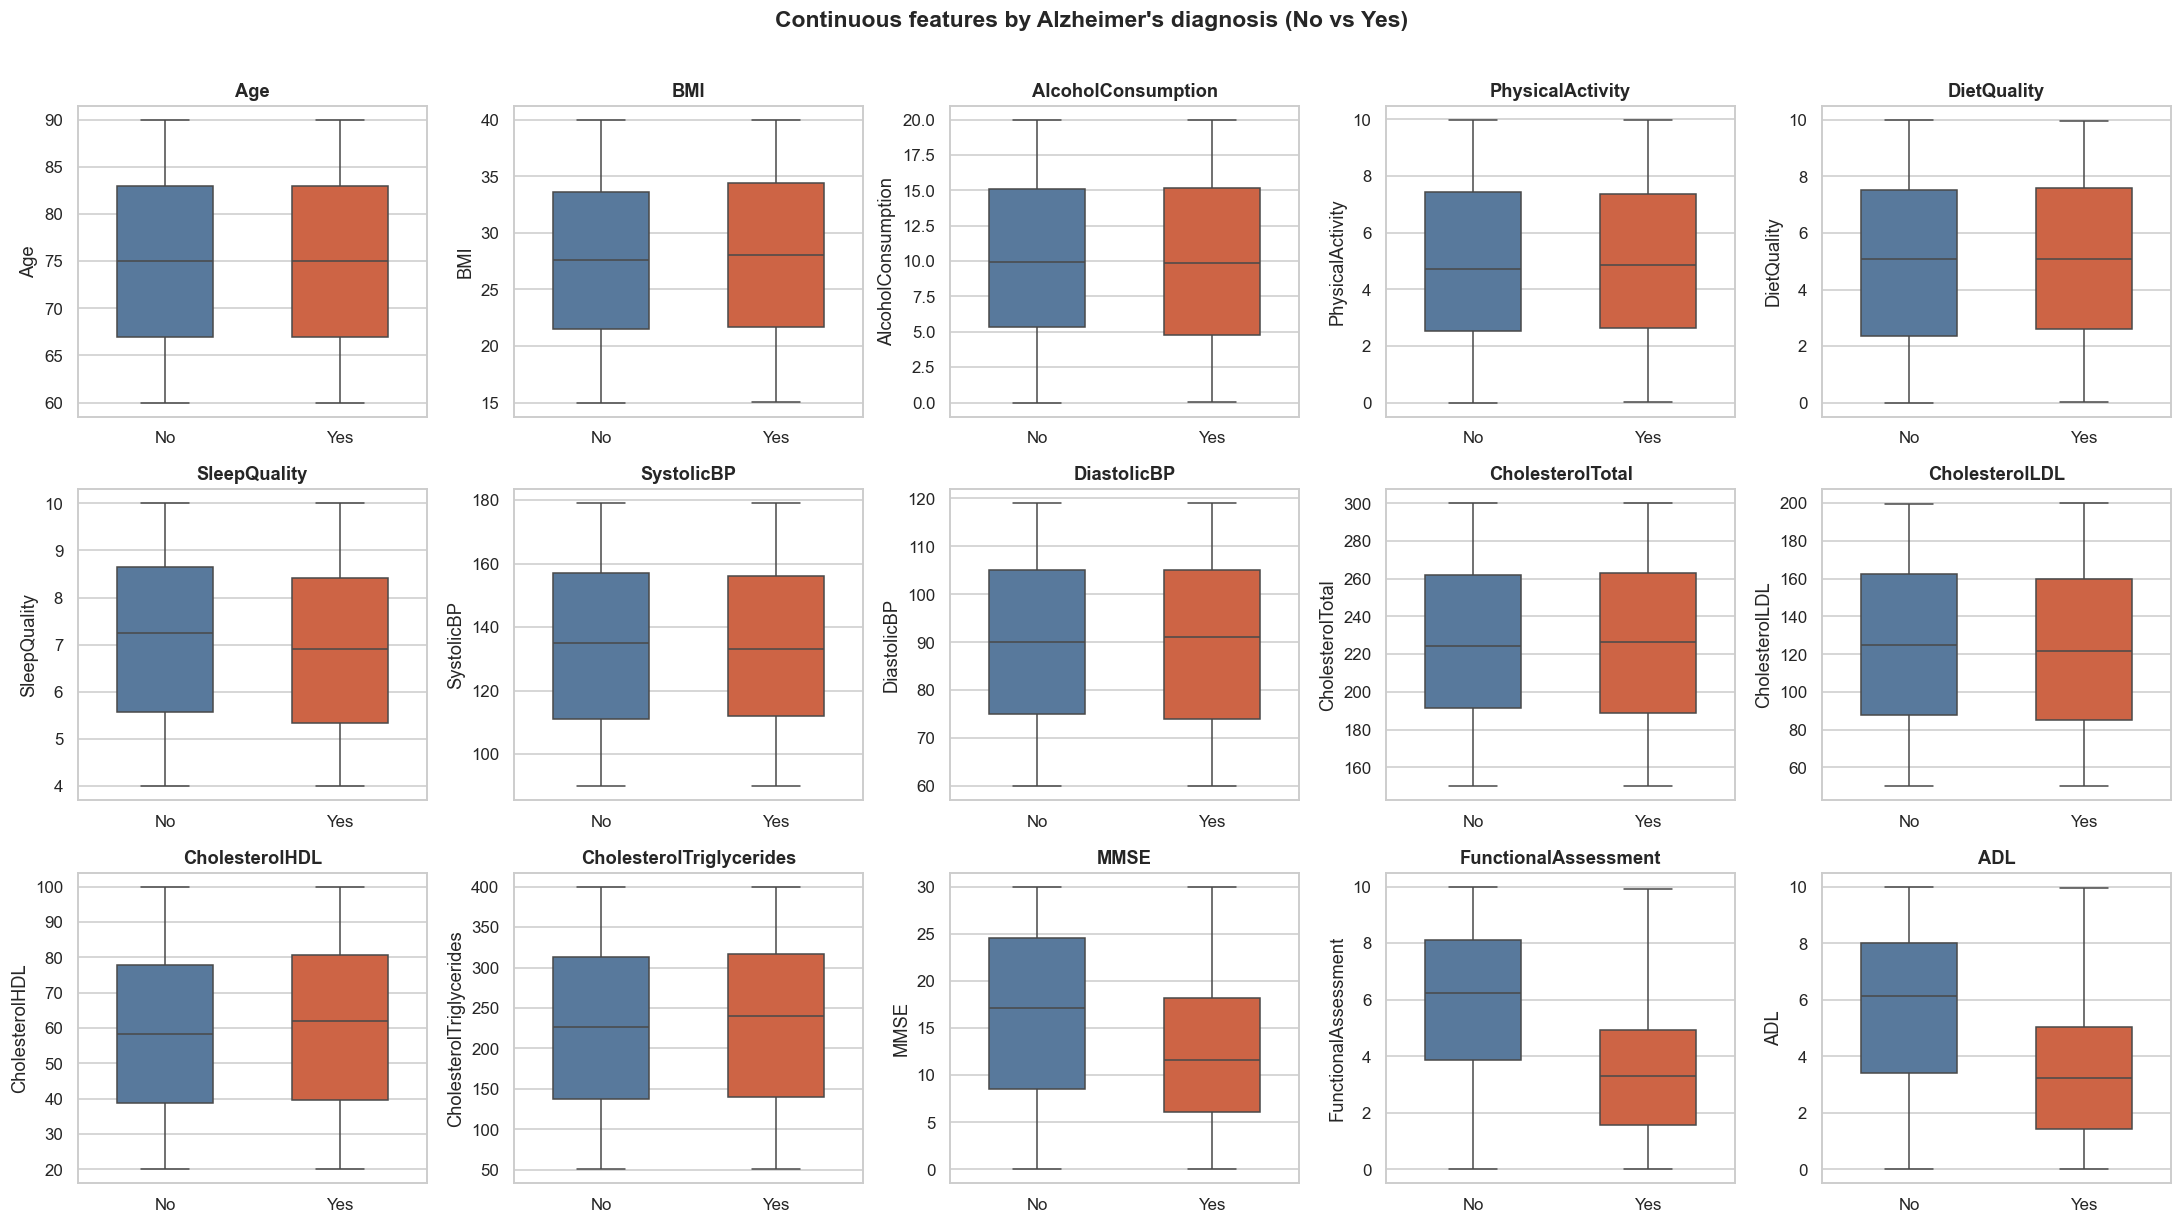

In [15]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, c in zip(axes.flat, CONTINUOUS):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=[PALETTE[0], PALETTE[1]], legend=False, ax=ax, width=.55, fliersize=2)
    ax.set_xticklabels(["No", "Yes"]); ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Continuous features by Alzheimer's diagnosis (No vs Yes)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 4.5 Statistical tests — which features differ between diagnosed and non-diagnosed patients?
- **Continuous features:** Mann-Whitney U test (no normality assumption) + Cohen's *d* as effect size.
- **Binary features:** χ² test of independence + Cramér's *V* as effect size.
- A Bonferroni-adjusted threshold is used because many tests are run at once.

In [16]:
g0, g1 = df[df[TARGET] == 0], df[df[TARGET] == 1]
alpha = 0.05 / (len(CONTINUOUS) + len(BINARY))   # Bonferroni

rows = []
for c in CONTINUOUS:
    a, b = g0[c], g1[c]
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    rows.append([c, a.mean(), b.mean(), (b.mean() - a.mean()) / pooled, stats.mannwhitneyu(a, b).pvalue])
cont_tests = pd.DataFrame(rows, columns=["feature", "mean_no_AD", "mean_AD", "cohens_d", "p_value"])
cont_tests["significant"] = cont_tests["p_value"] < alpha
cont_tests = cont_tests.reindex(cont_tests["cohens_d"].abs().sort_values(ascending=False).index).reset_index(drop=True)

rows = []
for c in BINARY:
    ct = pd.crosstab(df[c], df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append([c, df.loc[df[c] == 0, TARGET].mean() * 100, df.loc[df[c] == 1, TARGET].mean() * 100, v, p])
bin_tests = pd.DataFrame(rows, columns=["feature", "AD_rate_when_0_%", "AD_rate_when_1_%", "cramers_v", "p_value"])
bin_tests["significant"] = bin_tests["p_value"] < alpha
bin_tests = bin_tests.sort_values("cramers_v", ascending=False).reset_index(drop=True)

print(f"Bonferroni-adjusted alpha = {alpha:.5f}\n")
display(cont_tests); display(bin_tests)

Bonferroni-adjusted alpha = 0.00167



,feature,mean_no_AD,mean_AD,cohens_d,p_value,significant
0,FunctionalAssessment,5.861,3.653,-0.819,0.000,True
1,ADL,5.708,3.658,-0.737,0.000,True
2,MMSE,16.266,11.995,-0.510,0.000,True
3,SleepQuality,7.125,6.916,-0.118,0.009,False
4,CholesterolHDL,58.735,60.795,0.089,0.049,False
5,CholesterolLDL,125.361,122.462,-0.067,0.138,False
6,BMI,27.515,27.913,0.055,0.221,False
7,CholesterolTriglycerides,226.572,231.407,0.047,0.285,False
8,SystolicBP,134.564,133.717,-0.033,0.463,False
9,DietQuality,4.975,5.027,0.018,0.688,False


,feature,AD_rate_when_0_%,AD_rate_when_1_%,cramers_v,p_value,significant
0,MemoryComplaints,27.850,63.982,0.306,0.000,True
1,BehavioralProblems,30.740,60.237,0.223,0.000,True
2,Hypertension,34.664,39.375,0.034,0.118,False
3,FamilyHistoryAlzheimers,36.279,32.657,0.032,0.141,False
4,Diabetes,36.000,31.790,0.030,0.162,False
5,CardiovascularDisease,34.747,39.032,0.030,0.163,False
6,Disorientation,35.876,32.647,0.023,0.280,False
7,Gender,36.381,34.375,0.020,0.354,False
8,HeadInjury,35.692,32.161,0.020,0.360,False
9,PersonalityChanges,35.781,33.025,0.019,0.372,False


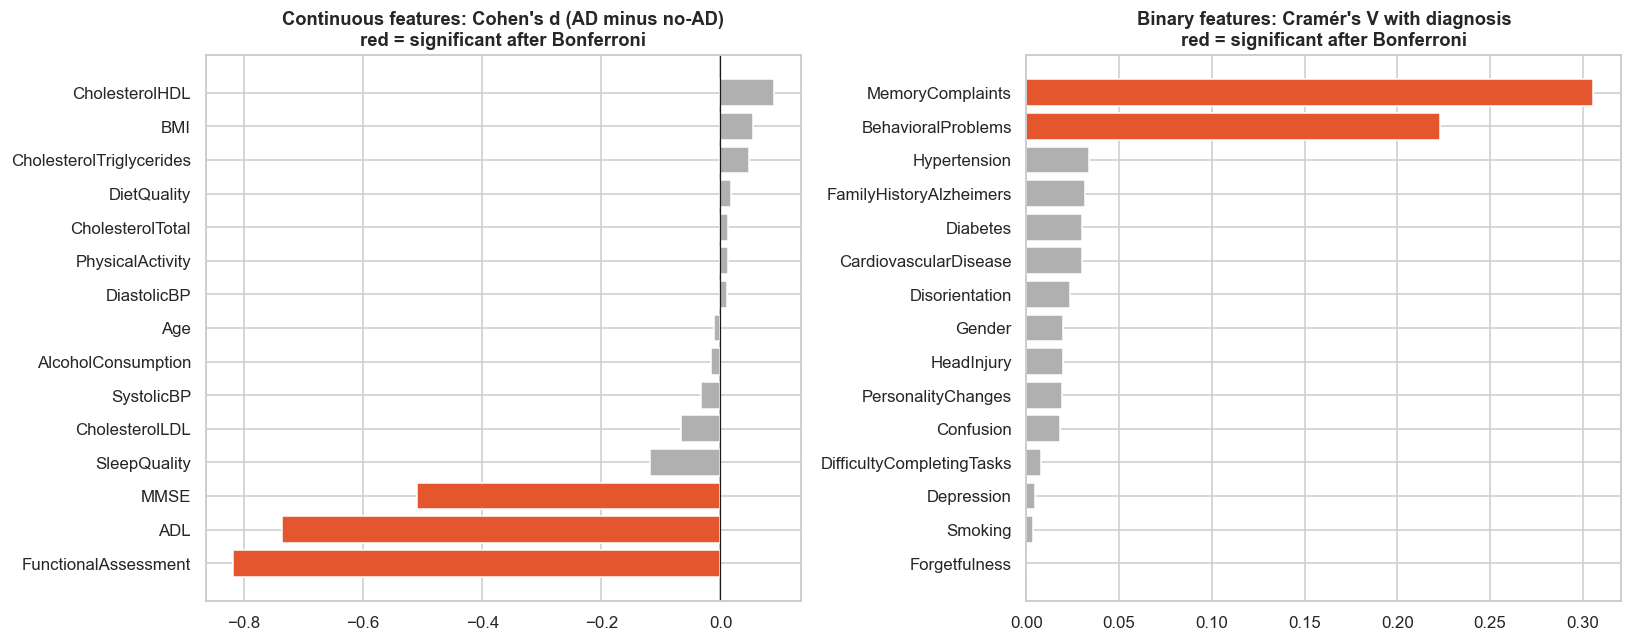

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ct = cont_tests.sort_values("cohens_d")
axes[0].barh(ct["feature"], ct["cohens_d"], color=np.where(ct["significant"], "#E4572E", "#B0B0B0"))
axes[0].axvline(0, color="k", lw=.8)
axes[0].set_title("Continuous features: Cohen's d (AD minus no-AD)\nred = significant after Bonferroni")
bt = bin_tests.sort_values("cramers_v")
axes[1].barh(bt["feature"], bt["cramers_v"], color=np.where(bt["significant"], "#E4572E", "#B0B0B0"))
axes[1].set_title("Binary features: Cramér's V with diagnosis\nred = significant after Bonferroni")
plt.tight_layout(); plt.show()

### 4.6 Binary features — Alzheimer's rate with vs. without each condition / symptom

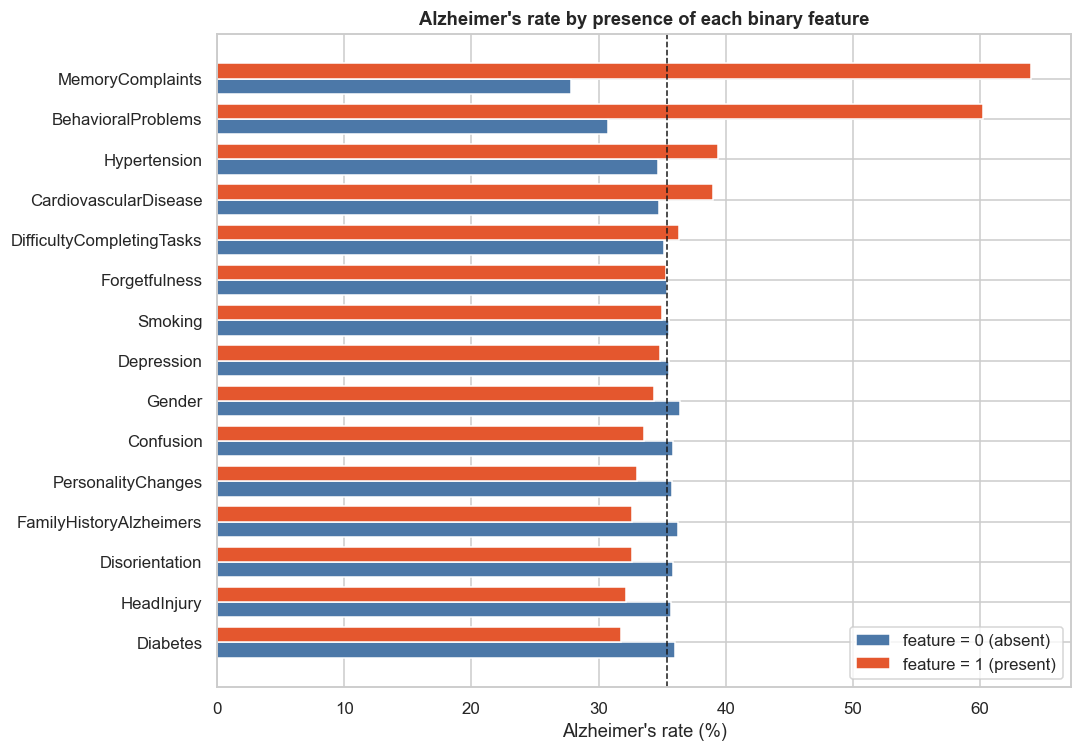

In [18]:
bt = bin_tests.sort_values("AD_rate_when_1_%")
y = np.arange(len(bt)); h = .38
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(y - h/2, bt["AD_rate_when_0_%"], h, label="feature = 0 (absent)", color=PALETTE[0])
ax.barh(y + h/2, bt["AD_rate_when_1_%"], h, label="feature = 1 (present)", color=PALETTE[1])
ax.set_yticks(y); ax.set_yticklabels(bt["feature"]); ax.axvline(df[TARGET].mean()*100, color="k", ls="--", lw=1)
ax.set_xlabel("Alzheimer's rate (%)"); ax.set_title("Alzheimer's rate by presence of each binary feature"); ax.legend()
plt.tight_layout(); plt.show()

### 4.7 Cognitive & functional scores (the strongest signals)

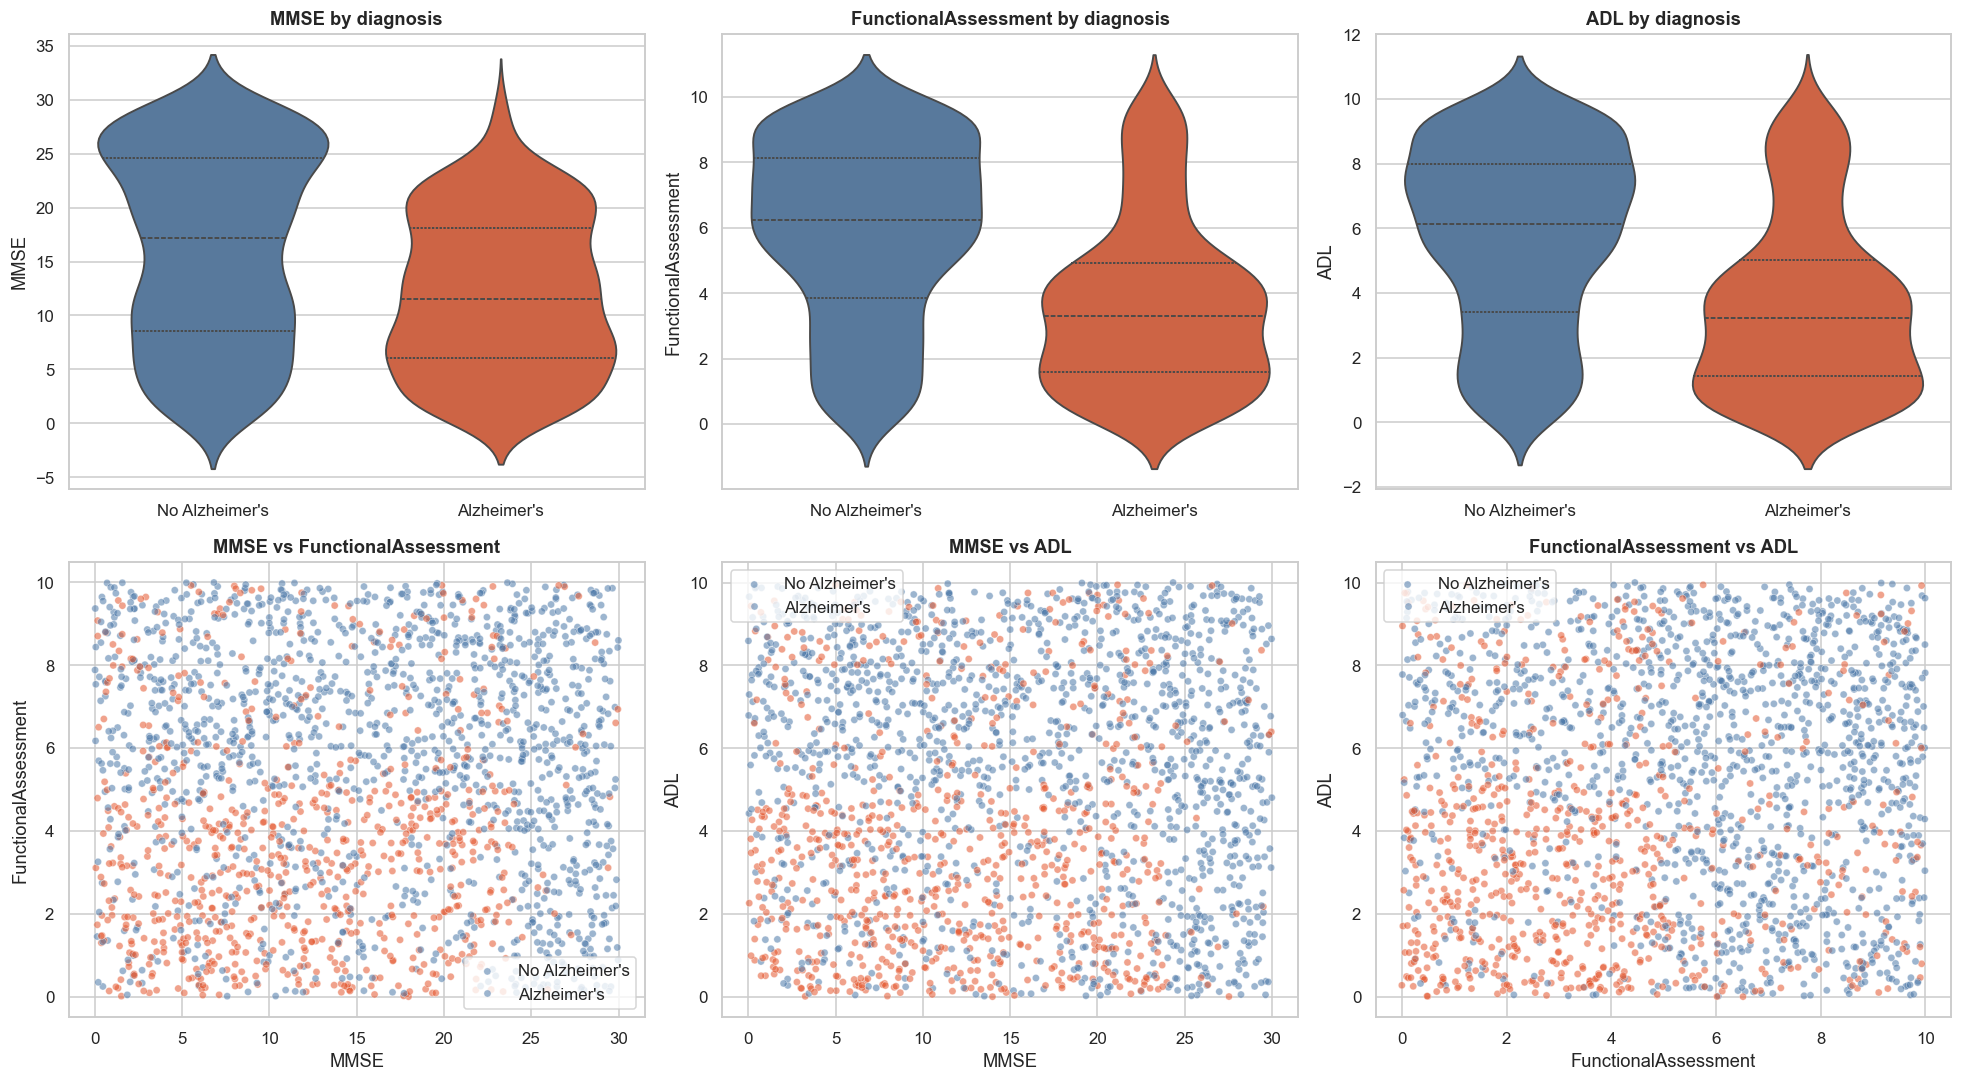

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes[0], ["MMSE", "FunctionalAssessment", "ADL"]):
    sns.violinplot(data=df, x=TARGET, y=c, hue=TARGET, palette=[PALETTE[0], PALETTE[1]], legend=False, inner="quartile", ax=ax)
    ax.set_xticklabels(["No Alzheimer's", "Alzheimer's"]); ax.set_xlabel(""); ax.set_title(f"{c} by diagnosis")
pairs = [("MMSE", "FunctionalAssessment"), ("MMSE", "ADL"), ("FunctionalAssessment", "ADL")]
for ax, (x, y) in zip(axes[1], pairs):
    sns.scatterplot(data=df, x=x, y=y, hue=TARGET, palette=PALETTE, alpha=.55, s=22, ax=ax)
    ax.set_title(f"{x} vs {y}"); ax.legend(title="", labels=[DIAG_LABELS[0], DIAG_LABELS[1]])
plt.tight_layout(); plt.show()

,AD_rate,patients
MMSE,,
Severe (0-9),0.451,683
Moderate (10-18),0.421,608
Mild (19-23),0.408,373
Normal (24-30),0.091,485


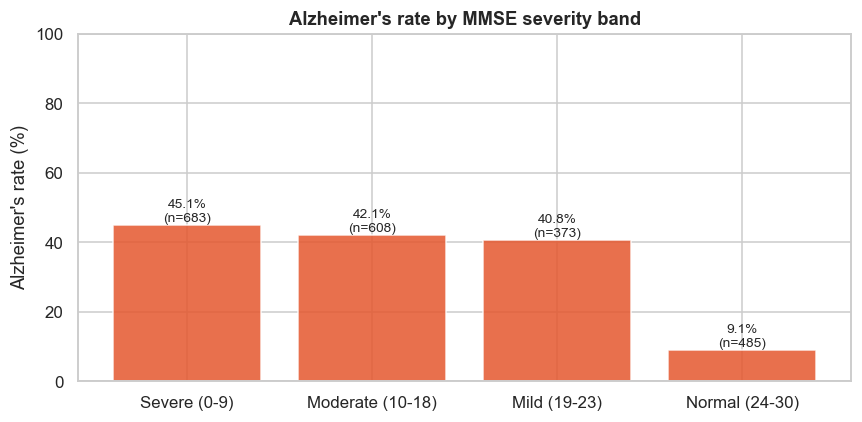

In [20]:
# Diagnosis rate across clinically meaningful MMSE bands
mmse_band = pd.cut(df["MMSE"], bins=[-0.1, 9, 18, 23, 30], labels=["Severe (0-9)", "Moderate (10-18)", "Mild (19-23)", "Normal (24-30)"])
band = df.groupby(mmse_band, observed=True)[TARGET].agg(["mean", "size"])
display(band.rename(columns={"mean": "AD_rate", "size": "patients"}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(band.index.astype(str), band["mean"] * 100, color="#E4572E", alpha=.85)
for i, (m, s) in enumerate(zip(band["mean"], band["size"])):
    ax.text(i, m * 100 + 1, f"{m*100:.1f}%\n(n={s})", ha="center", fontsize=9)
ax.set_ylim(0, 100); ax.set_ylabel("Alzheimer's rate (%)"); ax.set_title("Alzheimer's rate by MMSE severity band")
plt.tight_layout(); plt.show()

### 4.8 Symptom & comorbidity burden

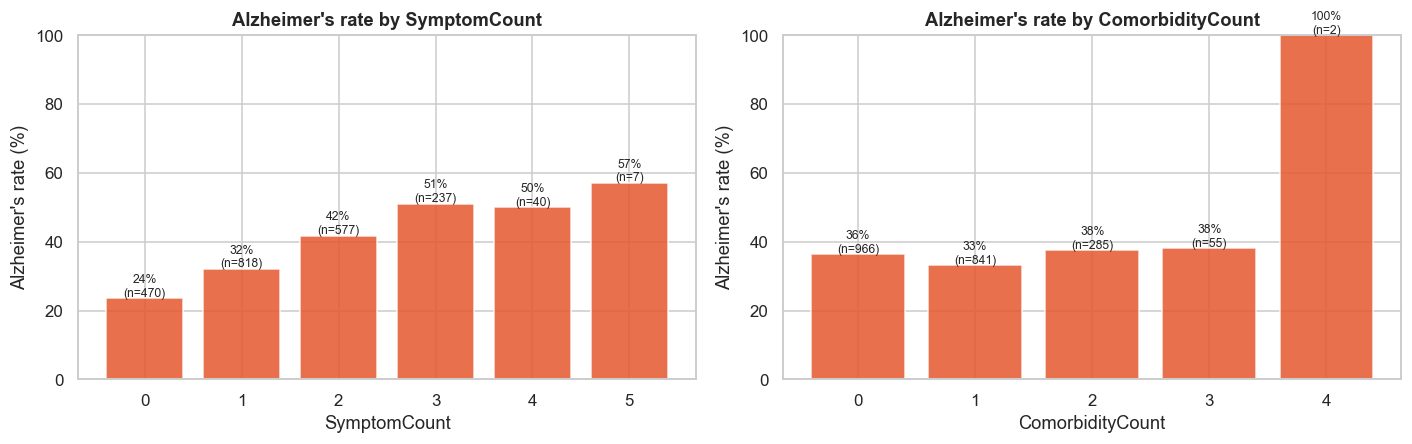

In [21]:
if "SymptomCount" in df:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, col in zip(axes, ["SymptomCount", "ComorbidityCount"]):
        r = df.groupby(col)[TARGET].agg(["mean", "size"])
        ax.bar(r.index.astype(str), r["mean"] * 100, color="#E4572E", alpha=.85)
        for i, (m, s) in enumerate(zip(r["mean"], r["size"])):
            ax.text(i, m * 100 + .5, f"{m*100:.0f}%\n(n={s})", ha="center", fontsize=8)
        ax.set_ylim(0, 100); ax.set_xlabel(col); ax.set_ylabel("Alzheimer's rate (%)")
        ax.set_title(f"Alzheimer's rate by {col}")
    plt.tight_layout(); plt.show()

### 4.9 Correlation analysis

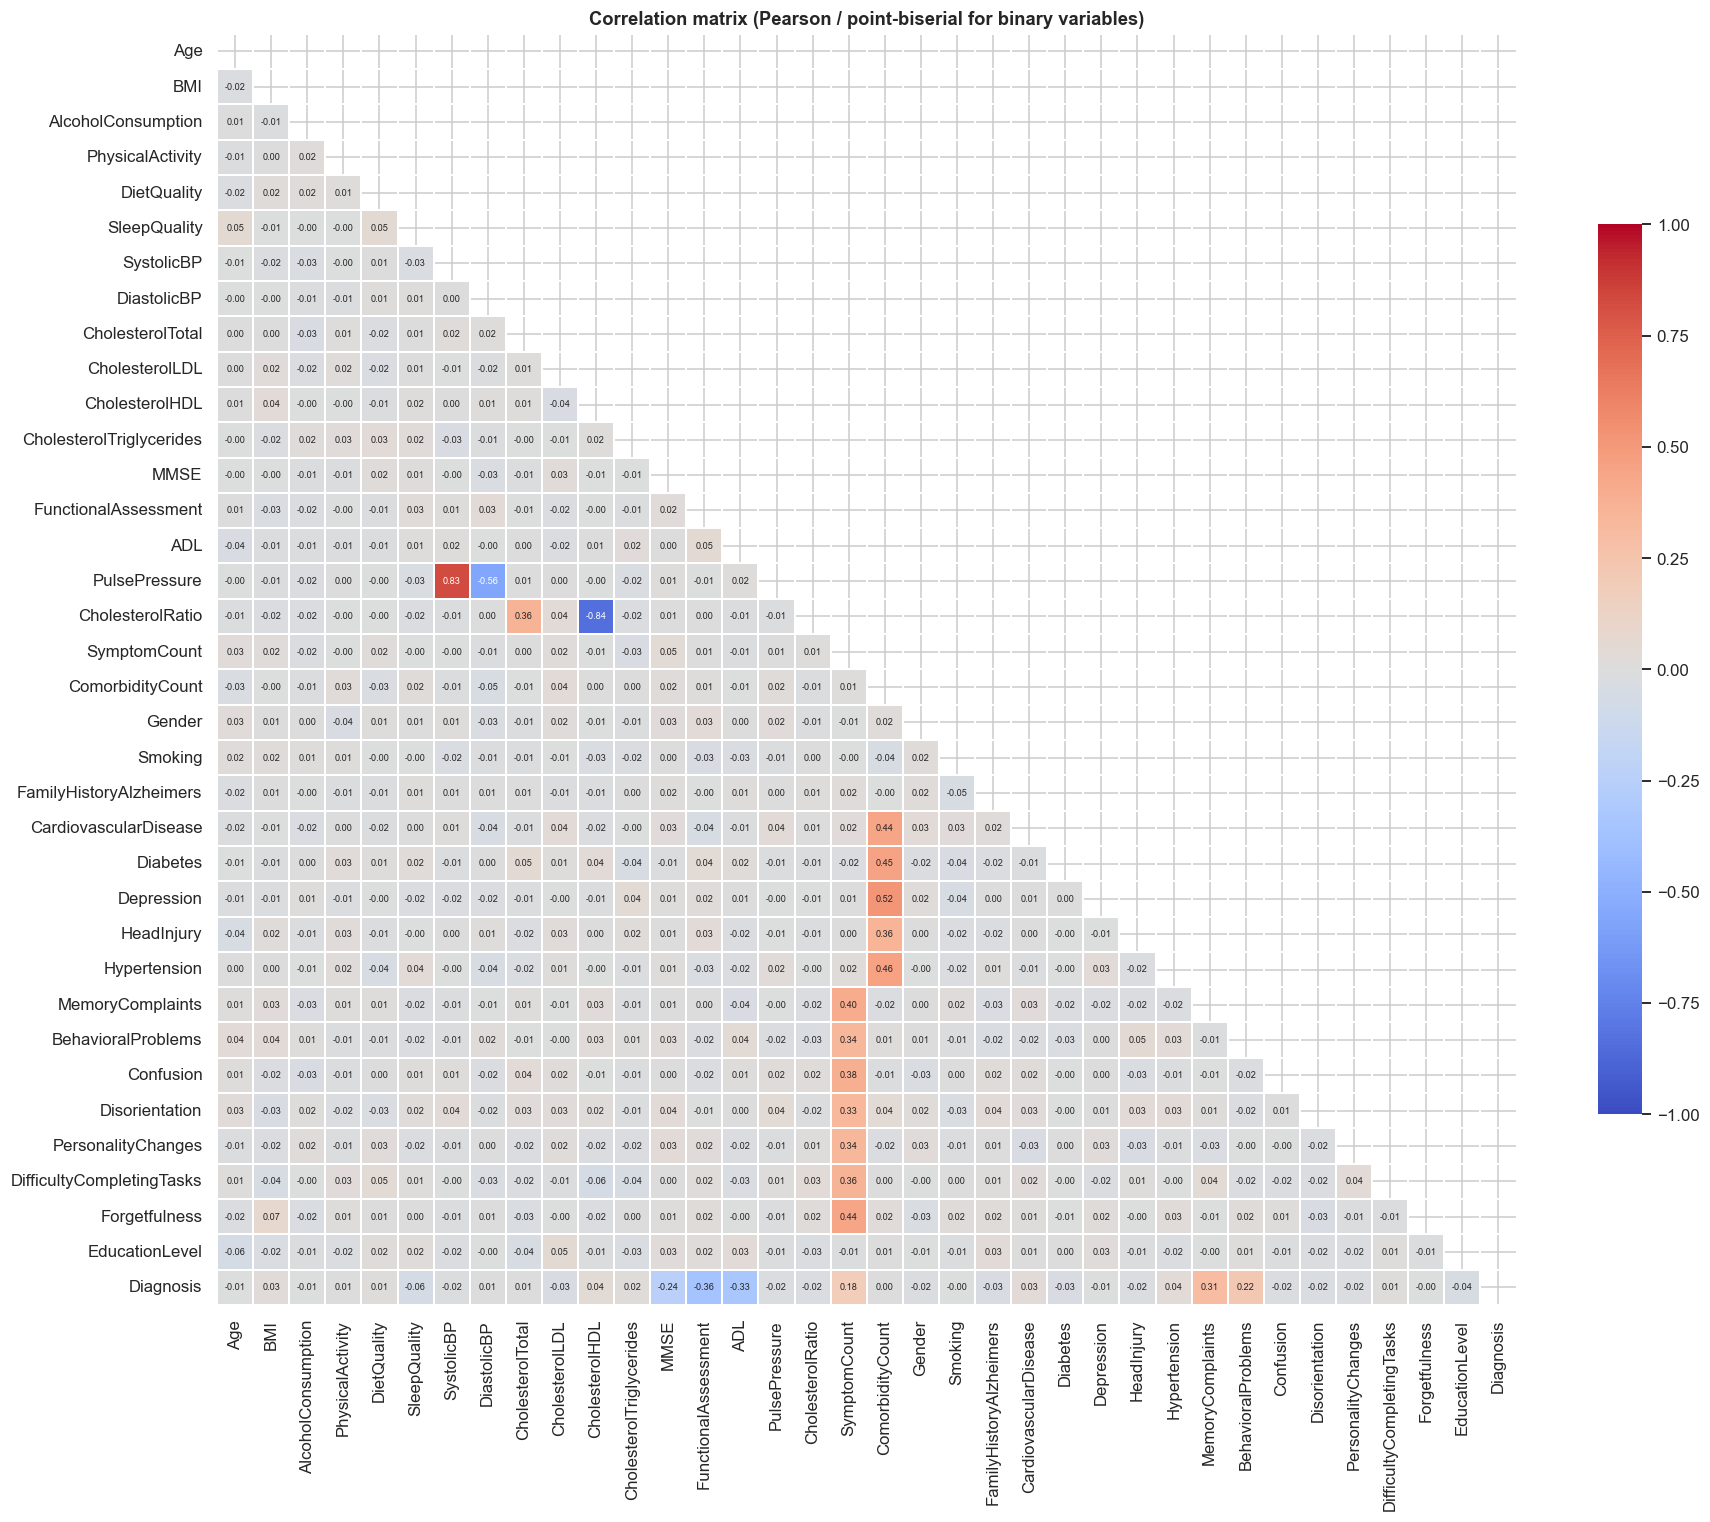

In [22]:
num_cols = CONTINUOUS + ENGINEERED_NUM + [c for c in ["SymptomCount", "ComorbidityCount"] if c in df] + BINARY + ORDINAL + [TARGET]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(17, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 6}, linewidths=.3, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlation matrix (Pearson / point-biserial for binary variables)")
plt.tight_layout(); plt.show()

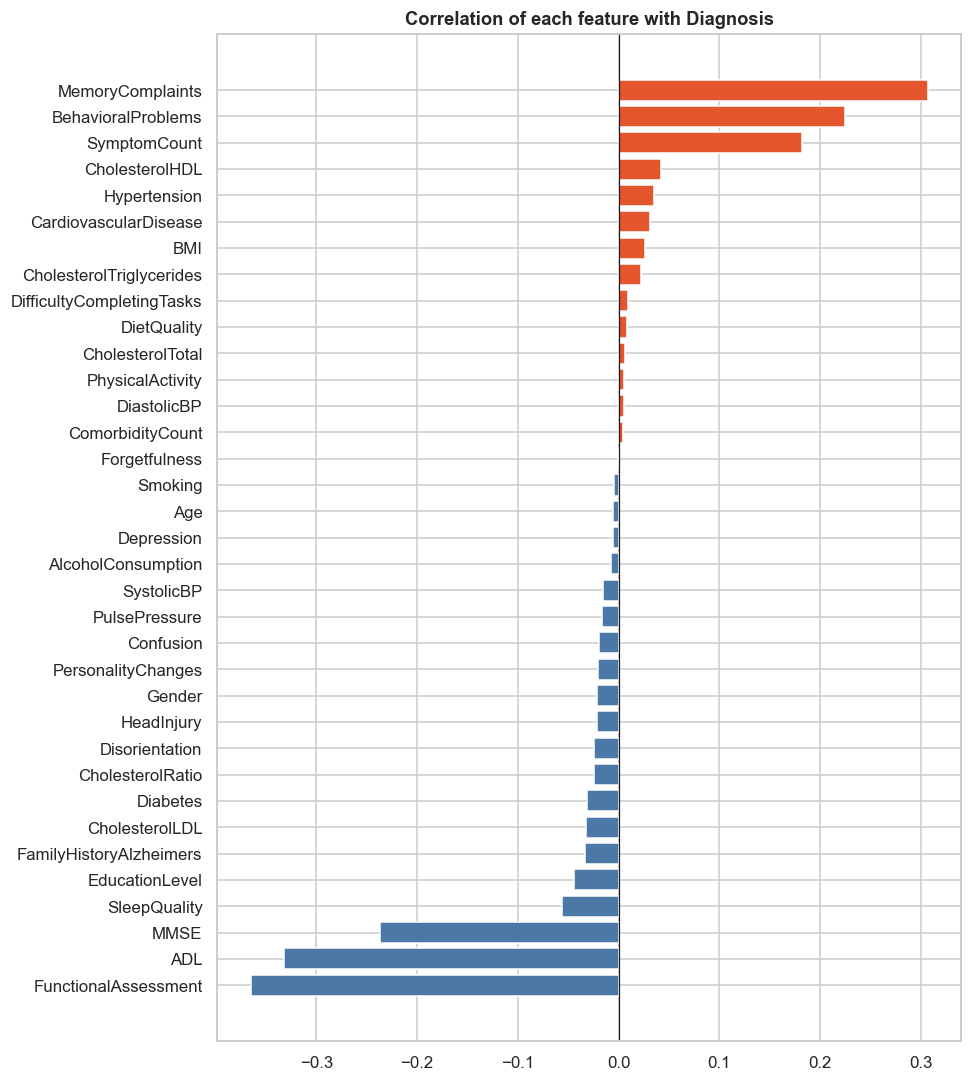

Top 8 absolute inter-feature correlations (excluding target):


corr
CholesterolHDL   CholesterolRatio      -0.841
SystolicBP       PulsePressure          0.827
DiastolicBP      PulsePressure         -0.560
ComorbidityCount Depression             0.523
                 Hypertension           0.455
                 Diabetes               0.450
SymptomCount     Forgetfulness          0.440
ComorbidityCount CardiovascularDisease  0.439

In [23]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(target_corr.index, target_corr.values, color=np.where(target_corr > 0, "#E4572E", "#4C78A8"))
ax.axvline(0, color="k", lw=.8); ax.set_title("Correlation of each feature with Diagnosis")
plt.tight_layout(); plt.show()

# strongest inter-feature correlations (potential redundancy)
pairs = corr.drop(columns=TARGET).drop(index=TARGET).where(np.triu(np.ones(corr.shape[0]-1), 1).astype(bool)).stack()
print("Top 8 absolute inter-feature correlations (excluding target):")
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).rename("corr").to_frame())

### 4.10 Feature importance (model-free) & multicollinearity

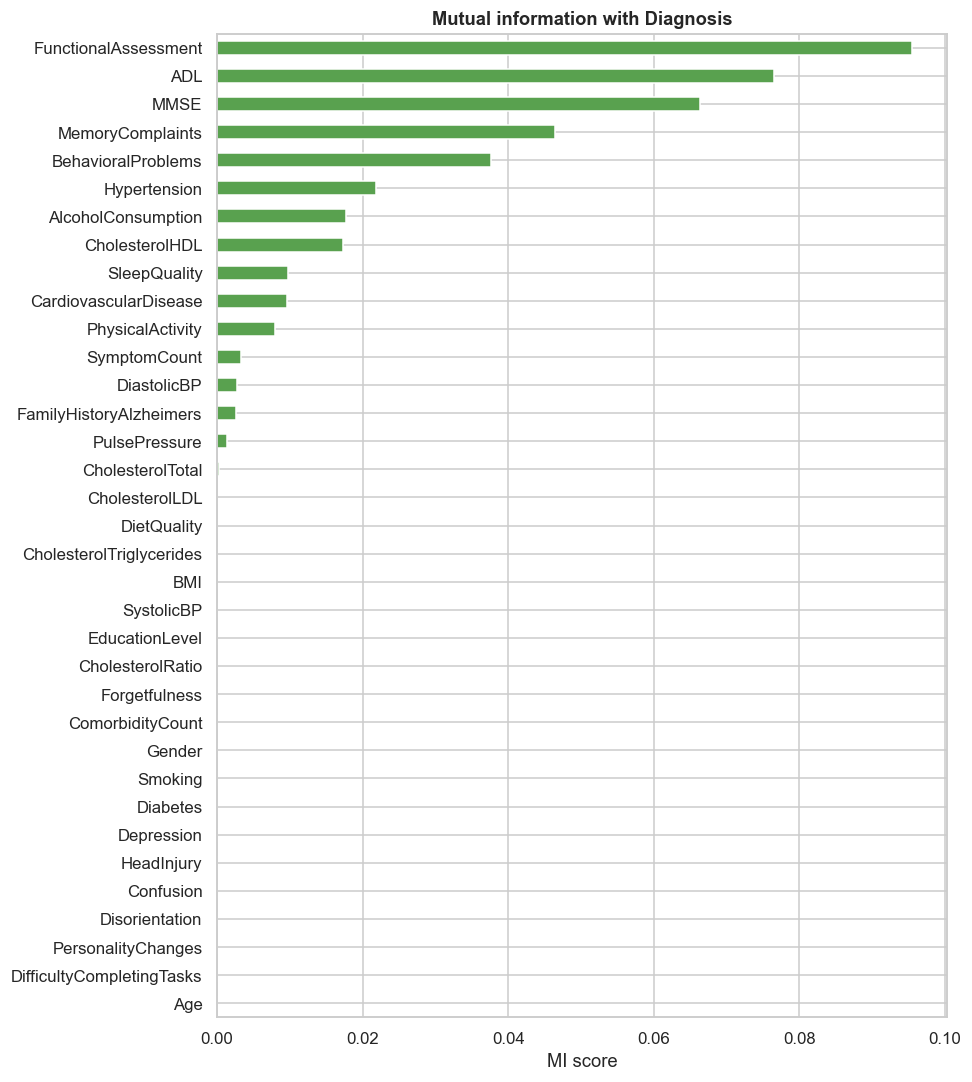

,feature,VIF
0,SleepQuality,1.008
1,DietQuality,1.007
2,FunctionalAssessment,1.007
3,ADL,1.006
4,CholesterolTriglycerides,1.006
5,Age,1.005
6,CholesterolLDL,1.005
7,BMI,1.005
8,AlcoholConsumption,1.004
9,SystolicBP,1.004


In [24]:
feat_cols = [c for c in num_cols if c != TARGET]
mi = pd.Series(mutual_info_classif(df[feat_cols], df[TARGET], random_state=RANDOM_STATE), index=feat_cols).sort_values()
fig, ax = plt.subplots(figsize=(9, 10))
mi.plot.barh(color="#59A14F", ax=ax); ax.set_title("Mutual information with Diagnosis"); ax.set_xlabel("MI score")
plt.tight_layout(); plt.show()

# Variance Inflation Factor for the continuous features (values > 5 suggest collinearity)
Xv = StandardScaler().fit_transform(df[CONTINUOUS])
vif = []
for i, c in enumerate(CONTINUOUS):
    others = np.delete(Xv, i, axis=1)
    r2 = LinearRegression().fit(others, Xv[:, i]).score(others, Xv[:, i])
    vif.append(1 / (1 - r2))
display(pd.DataFrame({"feature": CONTINUOUS, "VIF": vif}).sort_values("VIF", ascending=False).reset_index(drop=True))

### 4.11 Lifestyle & vitals — group means (standardised)

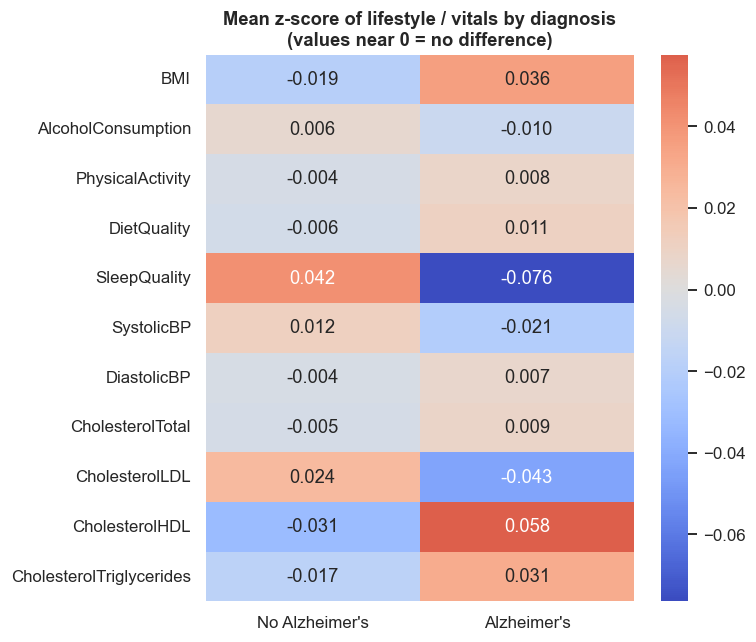

In [25]:
lifestyle = ["BMI", "AlcoholConsumption", "PhysicalActivity", "DietQuality", "SleepQuality",
             "SystolicBP", "DiastolicBP", "CholesterolTotal", "CholesterolLDL", "CholesterolHDL", "CholesterolTriglycerides"]
z = (df[lifestyle] - df[lifestyle].mean()) / df[lifestyle].std()
zm = z.groupby(df[TARGET]).mean().T
zm.columns = [DIAG_LABELS[c] for c in zm.columns]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(zm, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Mean z-score of lifestyle / vitals by diagnosis\n(values near 0 = no difference)")
plt.tight_layout(); plt.show()

### 4.12 Pairwise relationships among the top continuous predictors

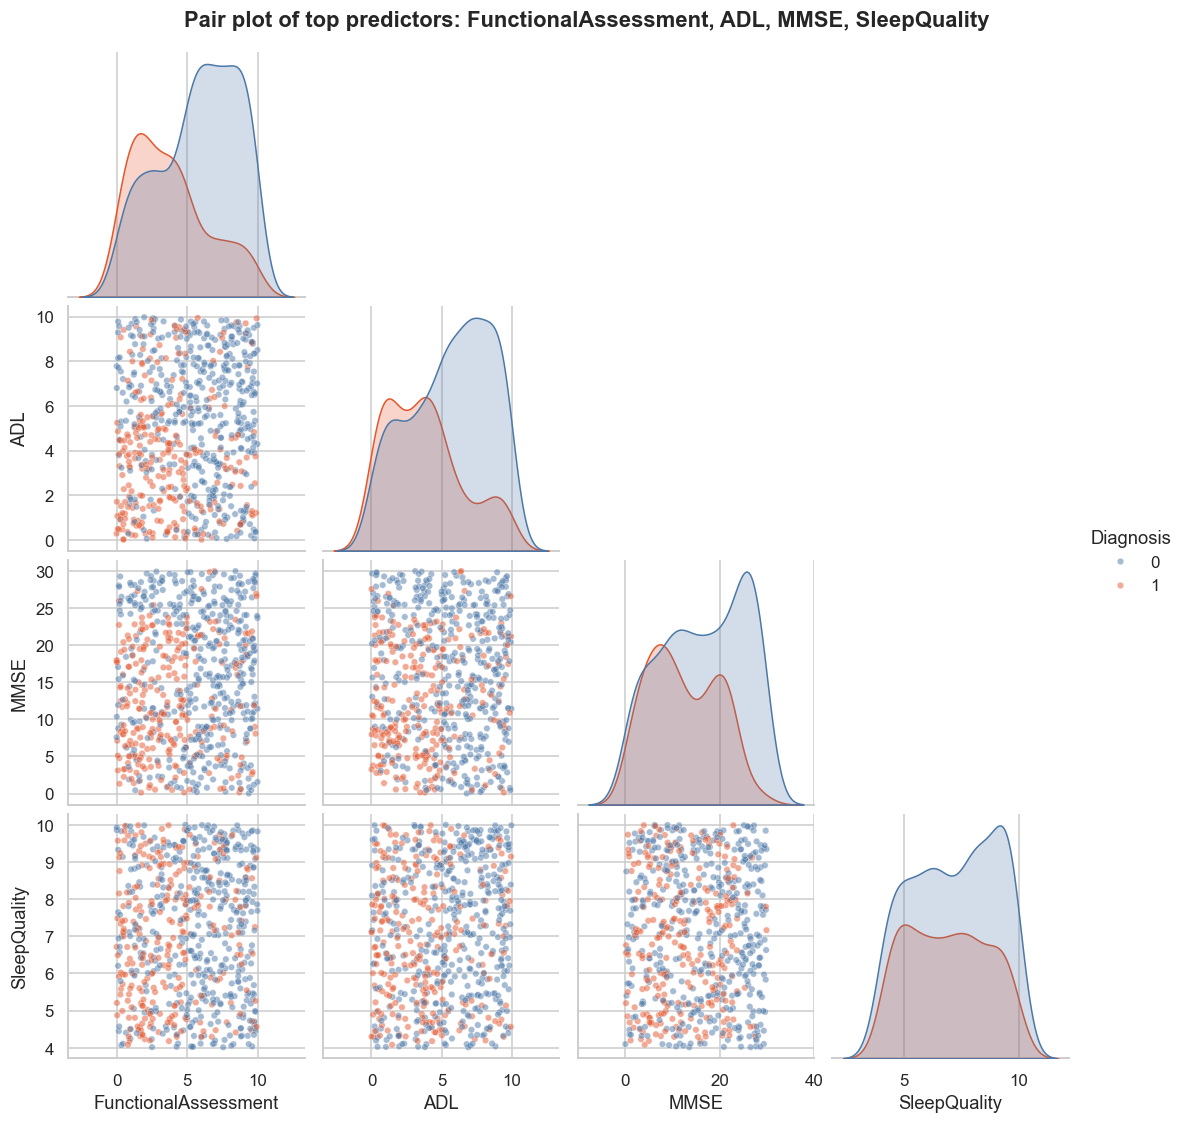

In [26]:
top4 = cont_tests["feature"].head(4).tolist()
sample = df.sample(min(700, len(df)), random_state=RANDOM_STATE)
g = sns.pairplot(sample[top4 + [TARGET]], hue=TARGET, palette=PALETTE, corner=True, plot_kws={"alpha": .5, "s": 18})
g.figure.suptitle(f"Pair plot of top predictors: {', '.join(top4)}", y=1.02, fontweight="bold")
plt.show()

## 5. ML-ready dataset: encoding, train/test split & scaling

- **Encoding:** `Ethnicity` is nominal → one-hot encoded; `EducationLevel` is ordinal → kept as 0-3; binary columns are already 0/1.
- **Split:** stratified 80/20 so both sets keep the same Alzheimer's ratio.
- **Scaling:** `StandardScaler` is **fit on the training set only** and then applied to the test set (prevents data leakage). Only continuous features are scaled.
- `AgeGroup` and `BMICategory` are EDA helpers and are excluded here (they duplicate `Age` and `BMI`).

In [27]:
ml = df.drop(columns=[c for c in ["AgeGroup", "BMICategory"] if c in df.columns])
ml = pd.get_dummies(ml, columns=NOMINAL, prefix="Ethnicity", dtype="int8")
ml = ml.rename(columns={f"Ethnicity_{k}": f"Ethnicity_{v.replace(' ', '')}" for k, v in LABELS["Ethnicity"].items()})

X = ml.drop(columns=[TARGET]); y = ml[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

scale_cols = CONTINUOUS + ENGINEERED_NUM
scaler = StandardScaler().fit(X_train[scale_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_s[scale_cols]  = scaler.transform(X_test[scale_cols])

print("ML-ready shape :", ml.shape)
print("Train / Test   :", X_train_s.shape, X_test_s.shape)
print("AD rate  train : %.3f | test : %.3f" % (y_train.mean(), y_test.mean()))
print("Scaled train means ~0:", round(float(X_train_s[scale_cols].mean().abs().max()), 6))
X_train_s.head()

ML-ready shape : (2149, 40)
Train / Test   : (1719, 39) (430, 39)
AD rate  train : 0.354 | test : 0.353
Scaled train means ~0: 0.0


,Age,Gender,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryAlzheimers,CardiovascularDisease,Diabetes,Depression,HeadInjury,Hypertension,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,PulsePressure,CholesterolRatio,SymptomCount,ComorbidityCount,Ethnicity_Caucasian,Ethnicity_AfricanAmerican,Ethnicity_Asian,Ethnicity_Other
780,1.231,0,1,0.065,0,1.478,0.571,-1.276,1.457,1,0,0,0,0,0,0.195,-0.235,0.059,-1.657,0.432,0.581,0.688,0.154,0,0,-1.603,0,0,0,0,1,0.294,-0.544,1,0,0,0,1,0
1341,-1.431,1,3,0.070,1,-0.407,-1.050,0.340,-1.136,0,0,0,0,0,0,1.622,1.201,1.499,1.191,-0.043,1.320,-0.667,1.435,0,0,-1.533,0,0,0,0,0,0.678,0.149,0,0,1,0,0,0
820,0.011,0,0,-0.317,0,-0.288,1.628,-1.119,0.513,0,1,1,1,0,0,-0.499,1.545,0.020,0.414,-1.533,-0.732,-0.318,-0.382,0,0,-0.020,0,0,0,0,0,-1.278,2.068,0,3,1,0,0,0
857,1.563,0,0,-0.567,0,-1.418,-1.257,1.280,1.255,0,0,0,0,0,0,1.391,-1.096,-0.159,-0.970,1.562,0.795,1.508,1.569,1,0,0.060,0,1,0,0,1,1.769,-0.958,3,0,1,0,0,0
593,0.122,1,2,1.534,1,-0.190,1.189,0.982,-0.632,0,0,1,0,0,1,-0.615,-0.522,-1.635,-0.220,-1.135,-0.750,1.247,1.202,0,0,1.498,0,0,0,0,1,-0.219,0.059,1,2,1,0,0,0


In [28]:
# ---------------- Export everything ----------------
ml.to_csv(os.path.join(OUTPUT_DIR, "alzheimers_ml_ready_unscaled.csv"), index=False)
X_train_s.to_csv(os.path.join(OUTPUT_DIR, "X_train_scaled.csv"), index=False)
X_test_s.to_csv(os.path.join(OUTPUT_DIR, "X_test_scaled.csv"), index=False)
y_train.to_csv(os.path.join(OUTPUT_DIR, "y_train.csv"), index=False)
y_test.to_csv(os.path.join(OUTPUT_DIR, "y_test.csv"), index=False)
joblib.dump(scaler, os.path.join(OUTPUT_DIR, "standard_scaler.joblib"))

# Statistical summaries produced during EDA
cont_tests.to_csv(os.path.join(OUTPUT_DIR, "eda_continuous_tests.csv"), index=False)
bin_tests.to_csv(os.path.join(OUTPUT_DIR, "eda_binary_tests.csv"), index=False)

print("Files saved in:", os.path.abspath(OUTPUT_DIR))
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f"  - {f:40s} {os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024:8.1f} KB")

# To reload later:
#   df_clean = pd.read_csv("cleaned_output/alzheimers_cleaned.csv")
#   scaler   = joblib.load("cleaned_output/standard_scaler.joblib")

Files saved in: C:\Users\Ankit\ADproject\cleaned_output
  - X_test_scaled.csv                           159.2 KB
  - X_train_scaled.csv                          634.7 KB
  - alzheimers_cleaned.csv                      658.5 KB
  - alzheimers_cleaned_labeled.csv              726.6 KB
  - alzheimers_ml_ready_unscaled.csv            641.6 KB
  - eda_binary_tests.csv                          1.4 KB
  - eda_continuous_tests.csv                      1.5 KB
  - standard_scaler.joblib                        1.5 KB
  - y_test.csv                                    1.3 KB
  - y_train.csv                                   5.0 KB


## 6. Key findings

Numbers below come from running this notebook on the 2,149-patient file (re-run to confirm if you change the data).

**Data quality**
- Clean to begin with: 0 missing values, 0 duplicate rows, 0 out-of-range values, 0 IQR outliers. Only `PatientID` (unique ID) and `DoctorInCharge` (single constant value) were dropped.
- Target is moderately imbalanced: 1,389 No-Alzheimer's vs 760 Alzheimer's (about 1.83 : 1, 35.4% positive) → use stratified splits and consider `class_weight="balanced"` / F1 / ROC-AUC rather than accuracy alone.

**What separates diagnosed from non-diagnosed patients**
- **Functional Assessment, ADL and MMSE are the strongest signals** (Cohen's *d* ≈ −0.82, −0.74, −0.51): diagnosed patients score clearly lower. All three stay significant after Bonferroni correction.
- **MMSE bands:** Alzheimer's rate is about 41-45% for MMSE below 24, but only about 9% for MMSE 24-30.
- **MemoryComplaints** (64% vs 28% Alzheimer's rate when absent) and **BehavioralProblems** (60% vs 31%) are the only binary features with a significant association (Cramér's *V* ≈ 0.31 and 0.22).

**What does *not* matter much in this dataset**
- Age, gender, ethnicity, education, BMI, blood pressure, cholesterol, smoking, alcohol, diet, physical activity and most other history/symptom flags show little or no difference between groups. Surprisingly, `Forgetfulness`, `Confusion` and `Disorientation` show essentially no association with diagnosis here.
- Continuous features are nearly independent of each other (all VIF ≈ 1.0), so multicollinearity is not a concern; the only high correlations are among engineered features built from raw columns (e.g. `PulsePressure` with `SystolicBP`).

**Implications for modelling**
- Expect a handful of features (FunctionalAssessment, ADL, MMSE, MemoryComplaints, BehavioralProblems) to drive almost all predictive power.
- MMSE, FunctionalAssessment and ADL are assessment results that are closely tied to how the diagnosis is made, so very high accuracy may partly reflect that. Compare a model with and without them to judge how useful it would be for early/risk screening.
- Fit scalers/encoders on the training set only (done in Section 5) to avoid leakage.

**Exported files (in `cleaned_output/`)**
| File | Contents |
|---|---|
| `alzheimers_cleaned.csv` | Cleaned data, original numeric codes, engineered features |
| `alzheimers_cleaned_labeled.csv` | Same, with readable labels (Male/Female, ethnicity, education, diagnosis) |
| `alzheimers_ml_ready_unscaled.csv` | One-hot encoded, ready for tree-based models |
| `X_train_scaled.csv`, `X_test_scaled.csv`, `y_train.csv`, `y_test.csv` | Stratified 80/20 split, standardised on train only |
| `standard_scaler.joblib` | Fitted scaler for reuse on new data |
| `eda_continuous_tests.csv`, `eda_binary_tests.csv` | Statistical test results |

## 7. Modelling setup — shared data & evaluation helpers
All team members' models below are trained on the **same** preprocessed split from Section 5 (`X_train_s`, `X_test_s`, `y_train`, `y_test`): 80/20 stratified, `random_state=42`, continuous features standardised (fit on train only), `Ethnicity` one-hot encoded. This makes every comparison fair.

The original team notebooks each re-loaded `alzheimers_cleaned.xls` and built their own `ColumnTransformer`. Since this notebook already produces the cleaned, encoded and scaled data, that step is replaced by the shared split — the model definitions and hyperparameters are kept as the teammates wrote them.

In [29]:
import time
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
try:
    from xgboost import XGBClassifier
except ImportError as e:
    raise ImportError("xgboost is not installed. Run  `pip install xgboost`  (or `%pip install xgboost` in a cell) and restart.") from e

CLASS_NAMES = ["No Alzheimer's", "Alzheimer's"]

def get_proba(model, X):
    """Probability of the positive class (falls back to decision_function if needed)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def compute_metrics(model, X, y_true, name):
    """One row of metrics for a fitted model on (X, y_true)."""
    y_pred = model.predict(X); y_prob = get_proba(model, X)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "Specificity": tn / (tn + fp),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "PR-AUC": average_precision_score(y_true, y_prob),
            "MCC": matthews_corrcoef(y_true, y_pred),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def evaluate_model(model, name, X=None, y_true=None, cmap="Blues"):
    """Print metrics + classification report and plot the confusion matrix (as in the team notebooks)."""
    X = X_test_s if X is None else X; y_true = y_test if y_true is None else y_true
    m = compute_metrics(model, X, y_true, name)
    print("=" * 50); print(name); print("=" * 50)
    for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
        print(f"{k:10s}: {m[k]:.4f}")
    print("\nClassification report:")
    print(classification_report(y_true, model.predict(X), target_names=CLASS_NAMES, zero_division=0))
    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    ConfusionMatrixDisplay(confusion_matrix(y_true, model.predict(X)), display_labels=CLASS_NAMES).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"{name} — Confusion Matrix"); plt.tight_layout(); plt.show()
    return m

baseline_rows = []     # collects one metrics row per baseline model
baseline_models = {}   # fitted baseline estimators
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape, "| Positive rate (train/test): %.3f / %.3f" % (y_train.mean(), y_test.mean()))

Train: (1719, 39) | Test: (430, 39) | Positive rate (train/test): 0.354 / 0.353


## 8. Baseline models — Random Forest & SVM  *(Dhruti)*
Default Random Forest and an RBF-kernel SVM (`C=1.0`, `gamma="scale"`).

Random Forest (baseline)
Accuracy  : 0.9372
Precision : 0.9433
Recall    : 0.8750
F1        : 0.9078
ROC-AUC   : 0.9439

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.93      0.97      0.95       278
   Alzheimer's       0.94      0.88      0.91       152

      accuracy                           0.94       430
     macro avg       0.94      0.92      0.93       430
  weighted avg       0.94      0.94      0.94       430



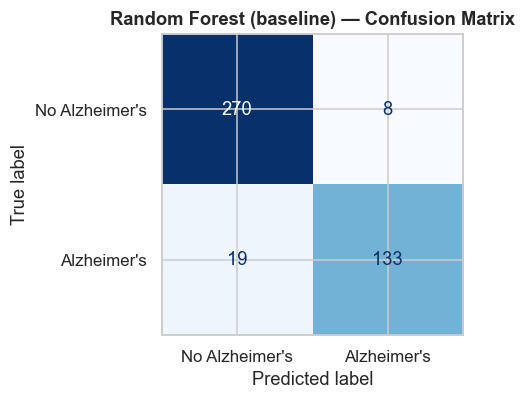

SVM (baseline)
Accuracy  : 0.8442
Precision : 0.8195
Recall    : 0.7171
F1        : 0.7649
ROC-AUC   : 0.9044

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.86      0.91      0.88       278
   Alzheimer's       0.82      0.72      0.76       152

      accuracy                           0.84       430
     macro avg       0.84      0.82      0.82       430
  weighted avg       0.84      0.84      0.84       430



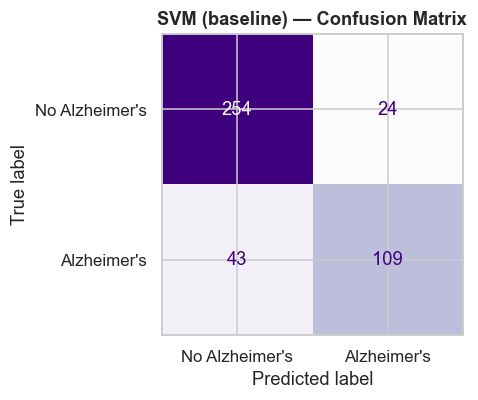

In [30]:
rf_base = RandomForestClassifier(random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_base = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
baseline_models.update({"Random Forest": rf_base, "SVM": svm_base})
baseline_rows += [evaluate_model(rf_base, "Random Forest (baseline)", cmap="Blues"),
                  evaluate_model(svm_base, "SVM (baseline)", cmap="Purples")]

## 9. Baseline models — KNN & XGBoost  *(Akshatha)*
KNN with `k=5` and XGBoost with the settings from the original notebook (300 trees, `learning_rate=0.05`, `max_depth=4`, `subsample=0.8`, `colsample_bytree=0.8`).

KNN (baseline)
Accuracy  : 0.7372
Precision : 0.6726
Recall    : 0.5000
F1        : 0.5736
ROC-AUC   : 0.7493

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.76      0.87      0.81       278
   Alzheimer's       0.67      0.50      0.57       152

      accuracy                           0.74       430
     macro avg       0.72      0.68      0.69       430
  weighted avg       0.73      0.74      0.73       430



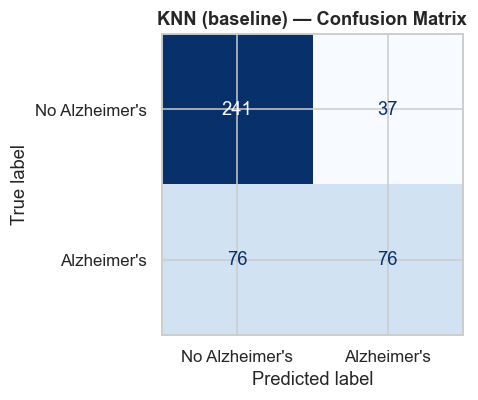

XGBoost (baseline)
Accuracy  : 0.9419
Precision : 0.9262
Recall    : 0.9079
F1        : 0.9169
ROC-AUC   : 0.9440

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.95      0.96      0.96       278
   Alzheimer's       0.93      0.91      0.92       152

      accuracy                           0.94       430
     macro avg       0.94      0.93      0.94       430
  weighted avg       0.94      0.94      0.94       430



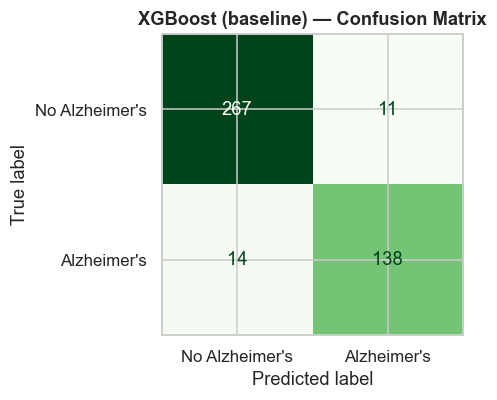

In [31]:
knn_base = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
xgb_base = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_s, y_train)
baseline_models.update({"KNN": knn_base, "XGBoost": xgb_base})
baseline_rows += [evaluate_model(knn_base, "KNN (baseline)", cmap="Blues"),
                  evaluate_model(xgb_base, "XGBoost (baseline)", cmap="Greens")]

## 10. Baseline models — HistGradientBoosting & GradientBoosting  *(Ankit)*
Both with scikit-learn defaults and a fixed seed.

HistGradientBoosting (baseline)
Accuracy  : 0.9512
Precision : 0.9396
Recall    : 0.9211
F1        : 0.9302
ROC-AUC   : 0.9522

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.96      0.97      0.96       278
   Alzheimer's       0.94      0.92      0.93       152

      accuracy                           0.95       430
     macro avg       0.95      0.94      0.95       430
  weighted avg       0.95      0.95      0.95       430



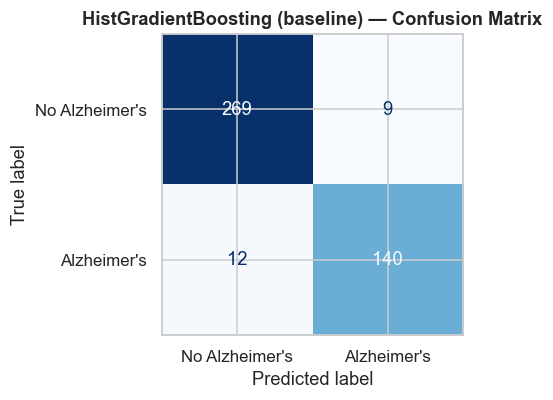

GradientBoosting (baseline)
Accuracy  : 0.9442
Precision : 0.9211
Recall    : 0.9211
F1        : 0.9211
ROC-AUC   : 0.9472

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.96      0.96      0.96       278
   Alzheimer's       0.92      0.92      0.92       152

      accuracy                           0.94       430
     macro avg       0.94      0.94      0.94       430
  weighted avg       0.94      0.94      0.94       430



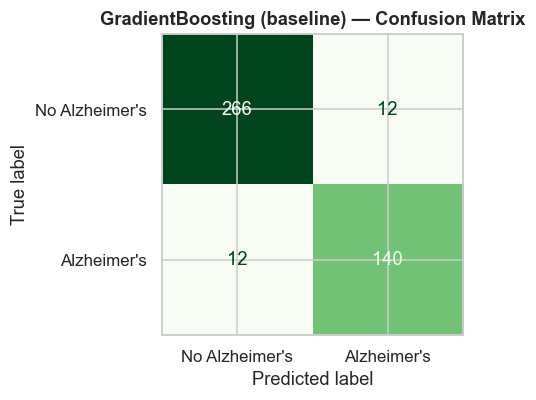

In [32]:
hgb_base = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_train_s, y_train)
gb_base = GradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_train_s, y_train)
baseline_models.update({"HistGradientBoosting": hgb_base, "GradientBoosting": gb_base})
baseline_rows += [evaluate_model(hgb_base, "HistGradientBoosting (baseline)", cmap="Blues"),
                  evaluate_model(gb_base, "GradientBoosting (baseline)", cmap="Greens")]

## 11. Baseline models — Logistic Regression & Naive Bayes  *(Aarti)*
Logistic Regression uses `class_weight="balanced"` and `max_iter=1000`, as in the original notebook. (The imputer step in the original pipeline is not needed here — the data has no missing values after Section 3.)

Logistic Regression (baseline)
Accuracy  : 0.8070
Precision : 0.6806
Recall    : 0.8553
F1        : 0.7580
ROC-AUC   : 0.8831

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.91      0.78      0.84       278
   Alzheimer's       0.68      0.86      0.76       152

      accuracy                           0.81       430
     macro avg       0.79      0.82      0.80       430
  weighted avg       0.83      0.81      0.81       430



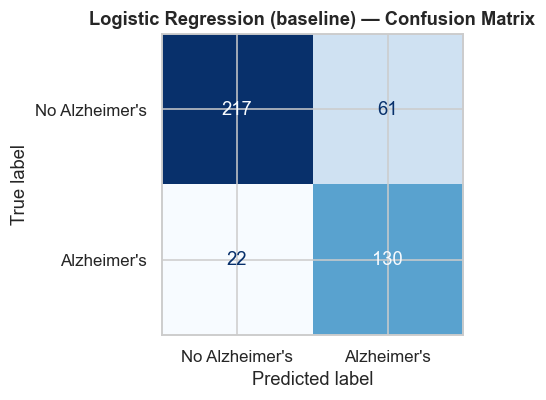

Naive Bayes (baseline)
Accuracy  : 0.7465
Precision : 0.6319
Recall    : 0.6776
F1        : 0.6540
ROC-AUC   : 0.8312

Classification report:
                precision    recall  f1-score   support

No Alzheimer's       0.82      0.78      0.80       278
   Alzheimer's       0.63      0.68      0.65       152

      accuracy                           0.75       430
     macro avg       0.72      0.73      0.73       430
  weighted avg       0.75      0.75      0.75       430



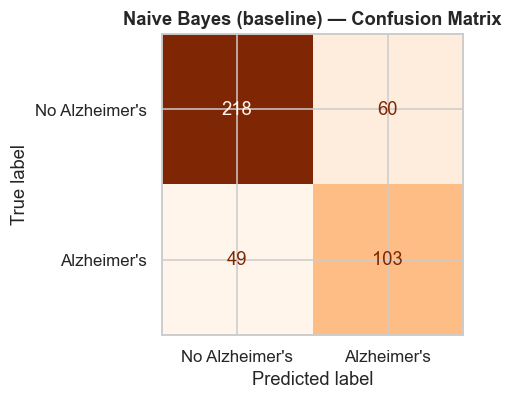

In [33]:
lr_base = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_s, y_train)
nb_base = GaussianNB().fit(X_train_s, y_train)
baseline_models.update({"Logistic Regression": lr_base, "Naive Bayes": nb_base})
baseline_rows += [evaluate_model(lr_base, "Logistic Regression (baseline)", cmap="Blues"),
                  evaluate_model(nb_base, "Naive Bayes (baseline)", cmap="Oranges")]

## 12. Baseline comparison — all 8 models
Everything below uses default / teammate-chosen hyperparameters and the untouched test set.

,Model,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,ROC-AUC,MCC
0,HistGradientBoosting,0.9512,0.9443,0.9396,0.9211,0.9676,0.9302,0.9522,0.8928
1,GradientBoosting,0.9442,0.9389,0.9211,0.9211,0.9568,0.9211,0.9472,0.8779
2,XGBoost,0.9419,0.9342,0.9262,0.9079,0.9604,0.9169,0.9440,0.8723
3,Random Forest,0.9372,0.9231,0.9433,0.8750,0.9712,0.9078,0.9439,0.8617
4,SVM,0.8442,0.8154,0.8195,0.7171,0.9137,0.7649,0.9044,0.6524
5,Logistic Regression,0.8070,0.8179,0.6806,0.8553,0.7806,0.7580,0.8831,0.6118
6,Naive Bayes,0.7465,0.7309,0.6319,0.6776,0.7842,0.6540,0.8312,0.4550
7,KNN,0.7372,0.6835,0.6726,0.5000,0.8669,0.5736,0.7493,0.3985


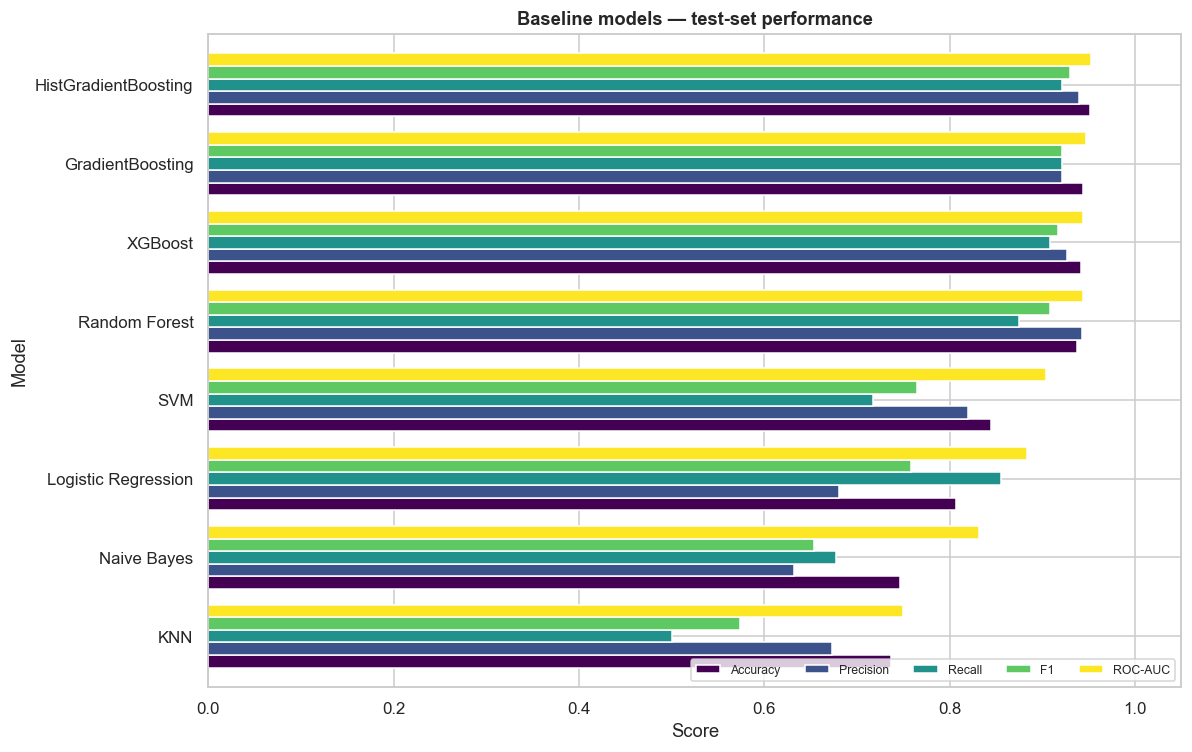

Top 3 baselines by F1: ['HistGradientBoosting', 'GradientBoosting', 'XGBoost']


In [34]:
baseline_df = pd.DataFrame(baseline_rows)
baseline_df["Model"] = baseline_df["Model"].str.replace(" (baseline)", "", regex=False)
show_cols = ["Model", "Accuracy", "Balanced Acc", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "MCC"]
display(baseline_df[show_cols].sort_values("F1", ascending=False).reset_index(drop=True).style
        .format({c: "{:.4f}" for c in show_cols[1:]}).background_gradient(cmap="YlGn", subset=show_cols[1:]))

plot_df = baseline_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].sort_values("F1")
ax = plot_df.plot(kind="barh", figsize=(11, 7), width=.8, colormap="viridis")
ax.set_xlim(0, 1.05); ax.set_xlabel("Score"); ax.set_title("Baseline models — test-set performance")
ax.legend(loc="lower right", ncol=5, fontsize=8); plt.tight_layout(); plt.show()

print("Top 3 baselines by F1:", baseline_df.sort_values("F1", ascending=False)["Model"].head(3).tolist())

## 13. Hyperparameter tuning — Random Forest, HistGradientBoosting, XGBoost

**Protocol**
- Tuning uses **only the training set** with **stratified 5-fold cross-validation**; the test set is not touched until the final evaluation (no leakage).
- Search method: `RandomizedSearchCV` (efficient on wide grids; raise `N_ITER` for a deeper search).
- Scoring metric: **F1** — the classes are imbalanced (~35% positive) so accuracy alone can be misleading. The best candidate is refit on the full training set.
- Class-imbalance handling (`class_weight` / `scale_pos_weight`) is itself part of the search space.

In [35]:
N_ITER = 60                      # candidates sampled per model (increase for a more exhaustive search)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "f1"
neg_pos_ratio = float((y_train == 0).sum() / (y_train == 1).sum())

search_spaces = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [200, 300, 500, 800],
         "max_depth": [None, 6, 8, 10, 14, 20],
         "min_samples_split": [2, 5, 10, 20],
         "min_samples_leaf": [1, 2, 4, 8],
         "max_features": ["sqrt", "log2", 0.3, 0.5],
         "class_weight": [None, "balanced", "balanced_subsample"],
         "bootstrap": [True, False]}),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {"learning_rate": [0.01, 0.02, 0.05, 0.08, 0.1, 0.2],
         "max_iter": [100, 200, 300, 500],
         "max_depth": [None, 3, 4, 6, 8],
         "max_leaf_nodes": [8, 15, 31, 63],
         "min_samples_leaf": [10, 20, 40, 60],
         "l2_regularization": [0.0, 0.1, 1.0, 5.0, 10.0],
         "class_weight": [None, "balanced"]}),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [200, 300, 500, 800],
         "learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2],
         "max_depth": [2, 3, 4, 5, 6],
         "min_child_weight": [1, 3, 5, 7],
         "subsample": [0.6, 0.8, 1.0],
         "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
         "gamma": [0, 0.1, 0.5, 1],
         "reg_alpha": [0, 0.1, 1],
         "reg_lambda": [1, 2, 5, 10],
         "scale_pos_weight": [1, round(neg_pos_ratio, 2)]}),
}

searches, tuned_models, tuning_time = {}, {}, {}
for name, (est, space) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, space, n_iter=N_ITER, scoring=SCORING, cv=CV, n_jobs=-1,
                            random_state=RANDOM_STATE, refit=True, return_train_score=True, verbose=0)
    rs.fit(X_train_s, y_train)
    searches[name], tuned_models[name] = rs, rs.best_estimator_
    tuning_time[name] = time.time() - t0
    print(f"{name:22s} best CV {SCORING.upper()} = {rs.best_score_:.4f}   ({tuning_time[name]:.0f}s)")
    print("   best params:", rs.best_params_)

Random Forest          best CV F1 = 0.9346   (986s)
   best params: {'n_estimators': 300, 'min_samples_split': 20, 'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 20, 'class_weight': 'balanced', 'bootstrap': True}
HistGradientBoosting   best CV F1 = 0.9365   (248s)
   best params: {'min_samples_leaf': 40, 'max_leaf_nodes': 8, 'max_iter': 500, 'max_depth': None, 'learning_rate': 0.01, 'l2_regularization': 1.0, 'class_weight': None}
XGBoost                best CV F1 = 0.9367   (134s)
   best params: {'subsample': 1.0, 'scale_pos_weight': 1, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.5}


### 13.1 Tuning results — best parameters and cross-validation behaviour

,Random Forest,HistGradientBoosting,XGBoost
bootstrap,True,—,—
class_weight,balanced,—,—
colsample_bytree,—,—,0.500
gamma,—,—,0.100
l2_regularization,—,1.000,—
learning_rate,—,0.010,0.050
max_depth,20,—,2.000
max_features,0.300,—,—
max_iter,—,500.000,—
max_leaf_nodes,—,8.000,—


,Baseline CV F1,Tuned CV F1,CV gain,Tuned CV std,Tuning time (s)
Model,,,,,
Random Forest,0.8952,0.9346,0.0394,0.0100,986
HistGradientBoosting,0.9322,0.9365,0.0043,0.0094,248
XGBoost,0.9338,0.9367,0.0029,0.0108,134


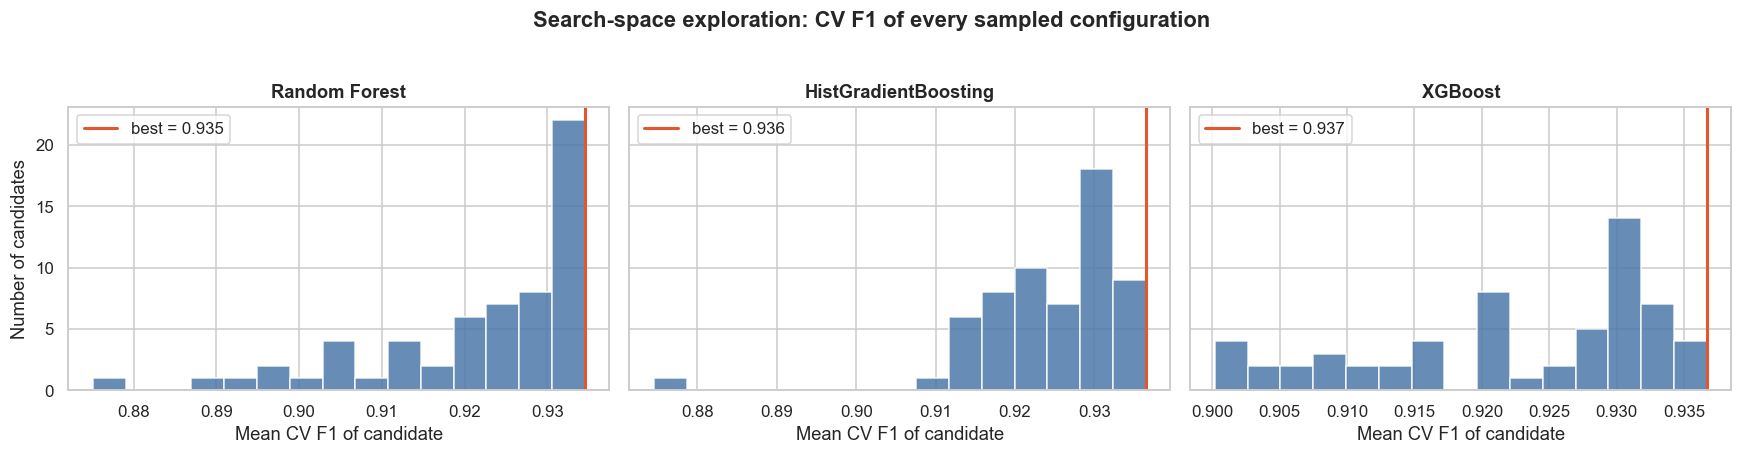

In [36]:
best_params_df = pd.DataFrame({n: pd.Series(s.best_params_) for n, s in searches.items()}).fillna("—")
display(best_params_df)

# CV F1 of the baseline model (same folds, same metric) vs the tuned model
cv_rows = []
for name, base in [("Random Forest", rf_base), ("HistGradientBoosting", hgb_base), ("XGBoost", xgb_base)]:
    base_cv = cross_val_score(base, X_train_s, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    cv_rows.append({"Model": name, "Baseline CV F1": base_cv.mean(), "Tuned CV F1": searches[name].best_score_,
                    "CV gain": searches[name].best_score_ - base_cv.mean(), "Tuned CV std": searches[name].cv_results_["std_test_score"][searches[name].best_index_],
                    "Tuning time (s)": tuning_time[name]})
cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df.style.format("{:.4f}", subset=["Baseline CV F1", "Tuned CV F1", "CV gain", "Tuned CV std"]).format("{:.0f}", subset=["Tuning time (s)"]))

# Distribution of CV scores explored during the search
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, s) in zip(axes, searches.items()):
    sc = pd.Series(s.cv_results_["mean_test_score"])
    ax.hist(sc, bins=15, color="#4C78A8", alpha=.85, edgecolor="white")
    ax.axvline(s.best_score_, color="#E4572E", lw=2, label=f"best = {s.best_score_:.3f}")
    ax.set_title(name); ax.set_xlabel("Mean CV F1 of candidate"); ax.legend()
axes[0].set_ylabel("Number of candidates")
plt.suptitle("Search-space exploration: CV F1 of every sampled configuration", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

## 14. Tuned-model comparison on the held-out test set
The three tuned models are scored for the first time on the test set, alongside their untuned baselines.

In [37]:
tuned_rows = [compute_metrics(m, X_test_s, y_test, n) for n, m in tuned_models.items()]
tuned_df = pd.DataFrame(tuned_rows).set_index("Model")

# add train-set F1 to expose over-fitting
tuned_df["Train F1"] = [f1_score(y_train, tuned_models[n].predict(X_train_s)) for n in tuned_df.index]
tuned_df["CV F1"] = [searches[n].best_score_ for n in tuned_df.index]
tuned_df["Train–Test F1 gap"] = tuned_df["Train F1"] - tuned_df["F1"]

metric_cols = ["Accuracy", "Balanced Acc", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "PR-AUC", "MCC"]
print("TUNED MODELS — test-set metrics")
display(tuned_df[metric_cols + ["CV F1", "Train F1", "Train–Test F1 gap"]].style
        .format("{:.4f}").background_gradient(cmap="YlGn", subset=metric_cols))

TUNED MODELS — test-set metrics


,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,MCC,CV F1,Train F1,Train–Test F1 gap
Model,,,,,,,,,,,,
Random Forest,0.9535,0.9461,0.9459,0.9211,0.9712,0.9333,0.9423,0.9228,0.8978,0.9346,0.9433,0.0100
HistGradientBoosting,0.9535,0.9476,0.9400,0.9276,0.9676,0.9338,0.9480,0.9390,0.8980,0.9365,0.9408,0.0070
XGBoost,0.9465,0.9393,0.9329,0.9145,0.9640,0.9236,0.9445,0.9353,0.8826,0.9367,0.9425,0.0190


### 14.1 Classification reports

In [38]:
for n, m in tuned_models.items():
    print("=" * 60); print(f"{n} (tuned)"); print("=" * 60)
    print(classification_report(y_test, m.predict(X_test_s), target_names=CLASS_NAMES, digits=4))

Random Forest (tuned)
                precision    recall  f1-score   support

No Alzheimer's     0.9574    0.9712    0.9643       278
   Alzheimer's     0.9459    0.9211    0.9333       152

      accuracy                         0.9535       430
     macro avg     0.9517    0.9461    0.9488       430
  weighted avg     0.9534    0.9535    0.9533       430

HistGradientBoosting (tuned)
                precision    recall  f1-score   support

No Alzheimer's     0.9607    0.9676    0.9642       278
   Alzheimer's     0.9400    0.9276    0.9338       152

      accuracy                         0.9535       430
     macro avg     0.9504    0.9476    0.9490       430
  weighted avg     0.9534    0.9535    0.9534       430

XGBoost (tuned)
                precision    recall  f1-score   support

No Alzheimer's     0.9537    0.9640    0.9589       278
   Alzheimer's     0.9329    0.9145    0.9236       152

      accuracy                         0.9465       430
     macro avg     0.9433    

### 14.2 Confusion matrices — tuned models (counts and row-normalised)

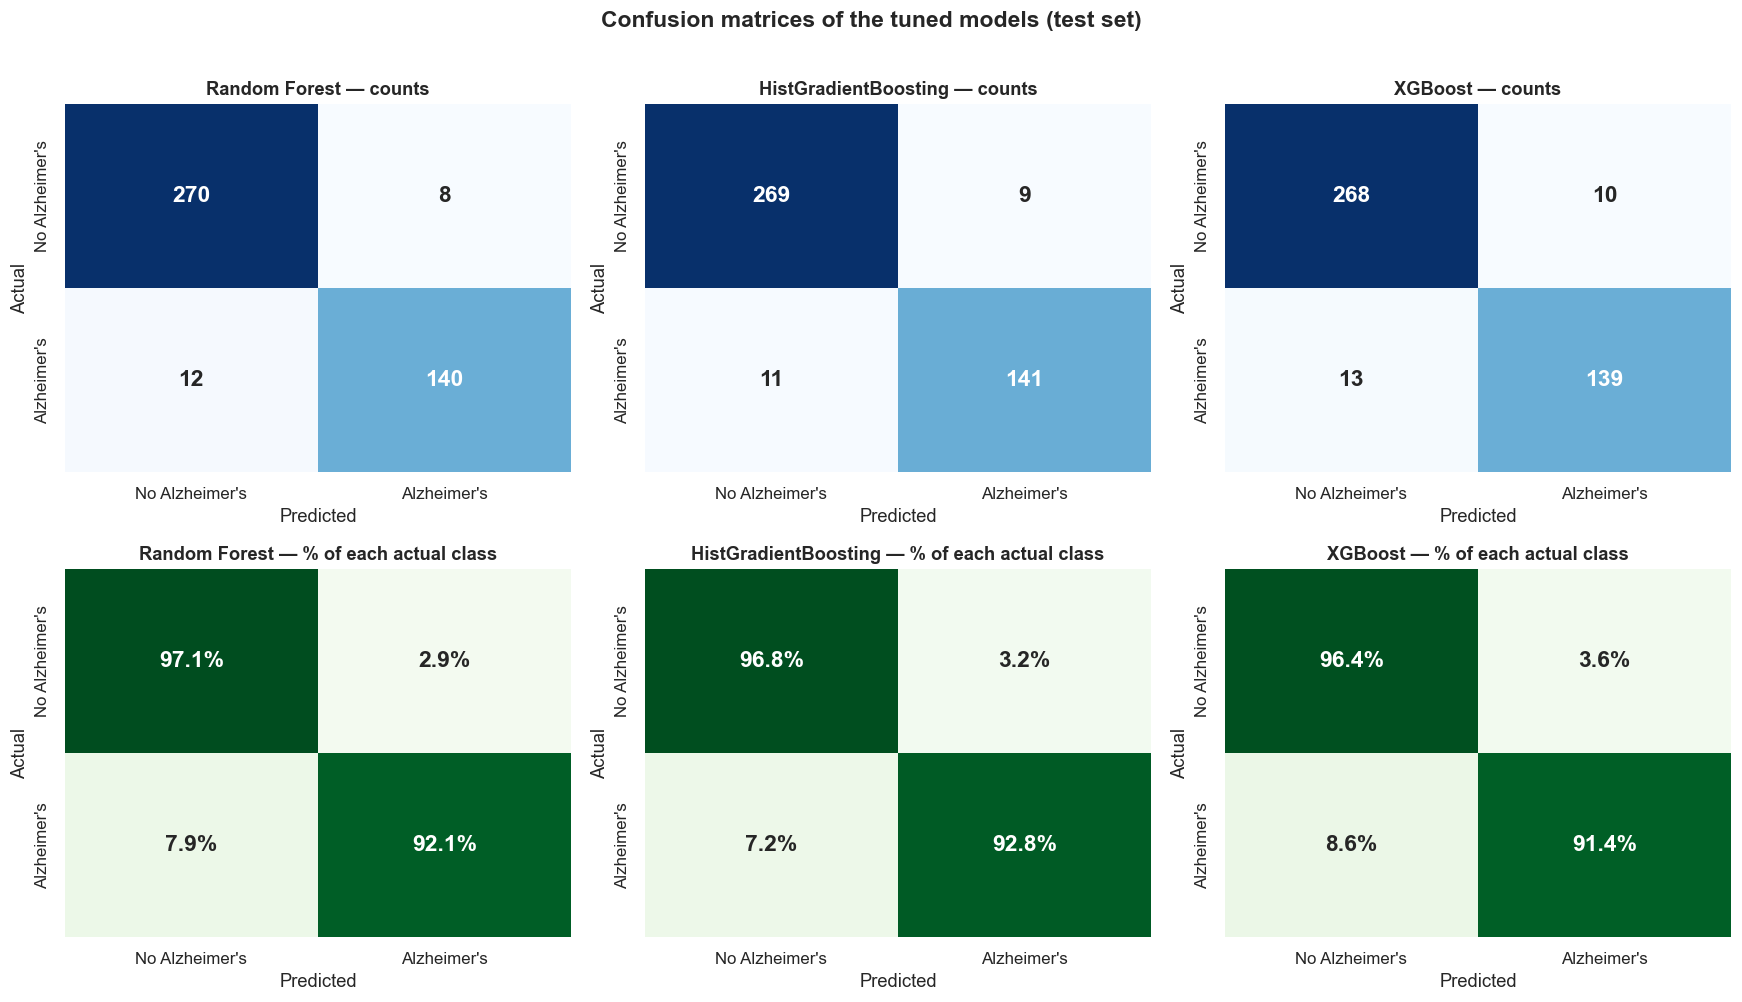

,True Neg,False Pos,False Neg (missed AD),True Pos
Model,,,,
Random Forest,270,8,12,140
HistGradientBoosting,269,9,11,141
XGBoost,268,10,13,139


In [39]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, (n, m) in enumerate(tuned_models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test_s))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, j], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                annot_kws={"size": 15, "weight": "bold"})
    axes[0, j].set_title(f"{n} — counts"); axes[0, j].set_xlabel("Predicted"); axes[0, j].set_ylabel("Actual")
    sns.heatmap(cmn, annot=True, fmt=".1%", cmap="Greens", cbar=False, vmin=0, vmax=1, ax=axes[1, j], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                annot_kws={"size": 15, "weight": "bold"})
    axes[1, j].set_title(f"{n} — % of each actual class"); axes[1, j].set_xlabel("Predicted"); axes[1, j].set_ylabel("Actual")
plt.suptitle("Confusion matrices of the tuned models (test set)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

display(tuned_df[["TN", "FP", "FN", "TP"]].astype(int).rename(columns={"TN": "True Neg", "FP": "False Pos", "FN": "False Neg (missed AD)", "TP": "True Pos"}))

### 14.3 Comparison charts

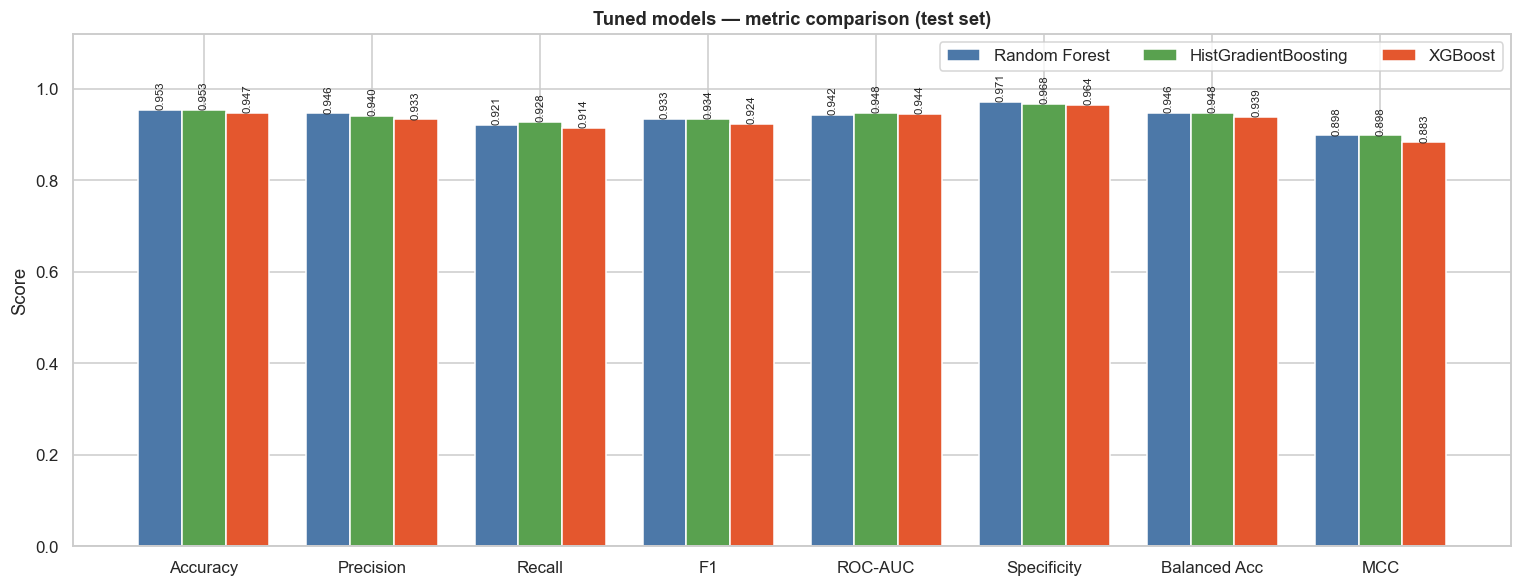

In [40]:
# (a) grouped bars — all key metrics
main = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Specificity", "Balanced Acc", "MCC"]
colors = {"Random Forest": "#4C78A8", "HistGradientBoosting": "#59A14F", "XGBoost": "#E4572E"}
x = np.arange(len(main)); w = .26
fig, ax = plt.subplots(figsize=(14, 5.5))
for i, n in enumerate(tuned_df.index):
    vals = tuned_df.loc[n, main].values.astype(float)
    bars = ax.bar(x + (i - 1) * w, vals, w, label=n, color=colors[n])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.3f}", ha="center", fontsize=7.5, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(main); ax.set_ylim(0, 1.12); ax.set_ylabel("Score")
ax.set_title("Tuned models — metric comparison (test set)", fontweight="bold"); ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

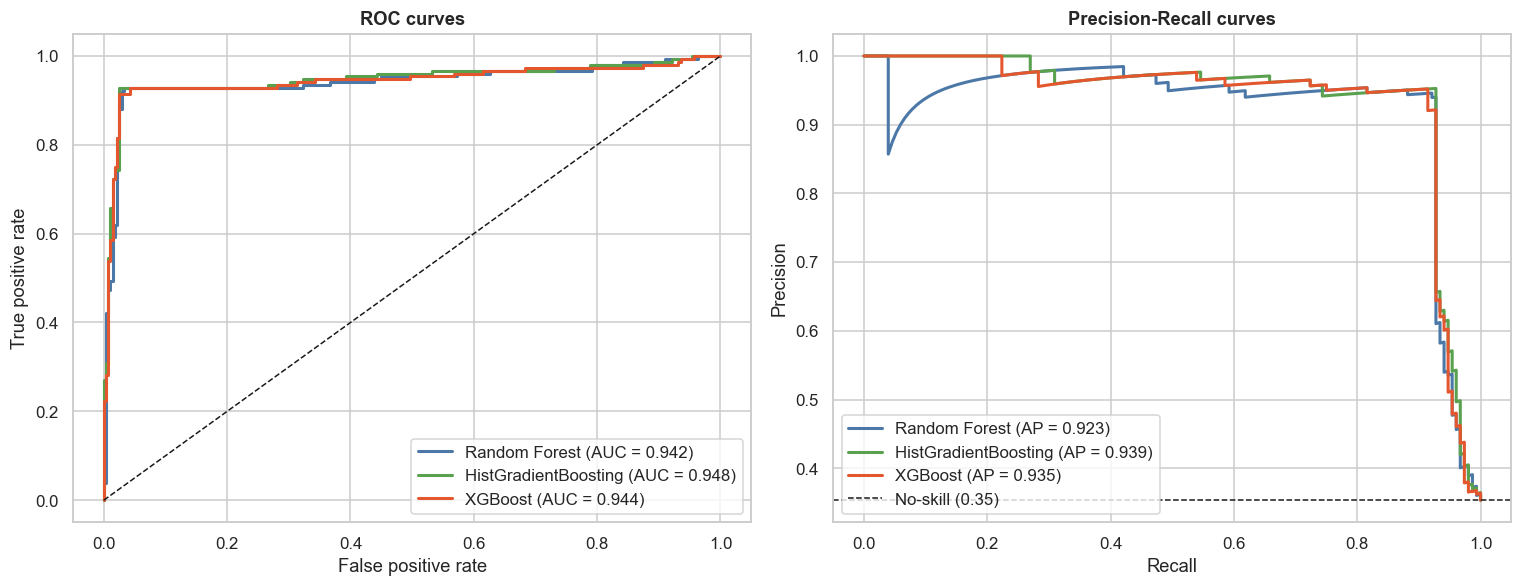

In [41]:
# (b) ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for n, m in tuned_models.items():
    p = get_proba(m, X_test_s)
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, lw=2, color=colors[n], label=f"{n} (AUC = {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, lw=2, color=colors[n], label=f"{n} (AP = {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No-skill ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curves"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

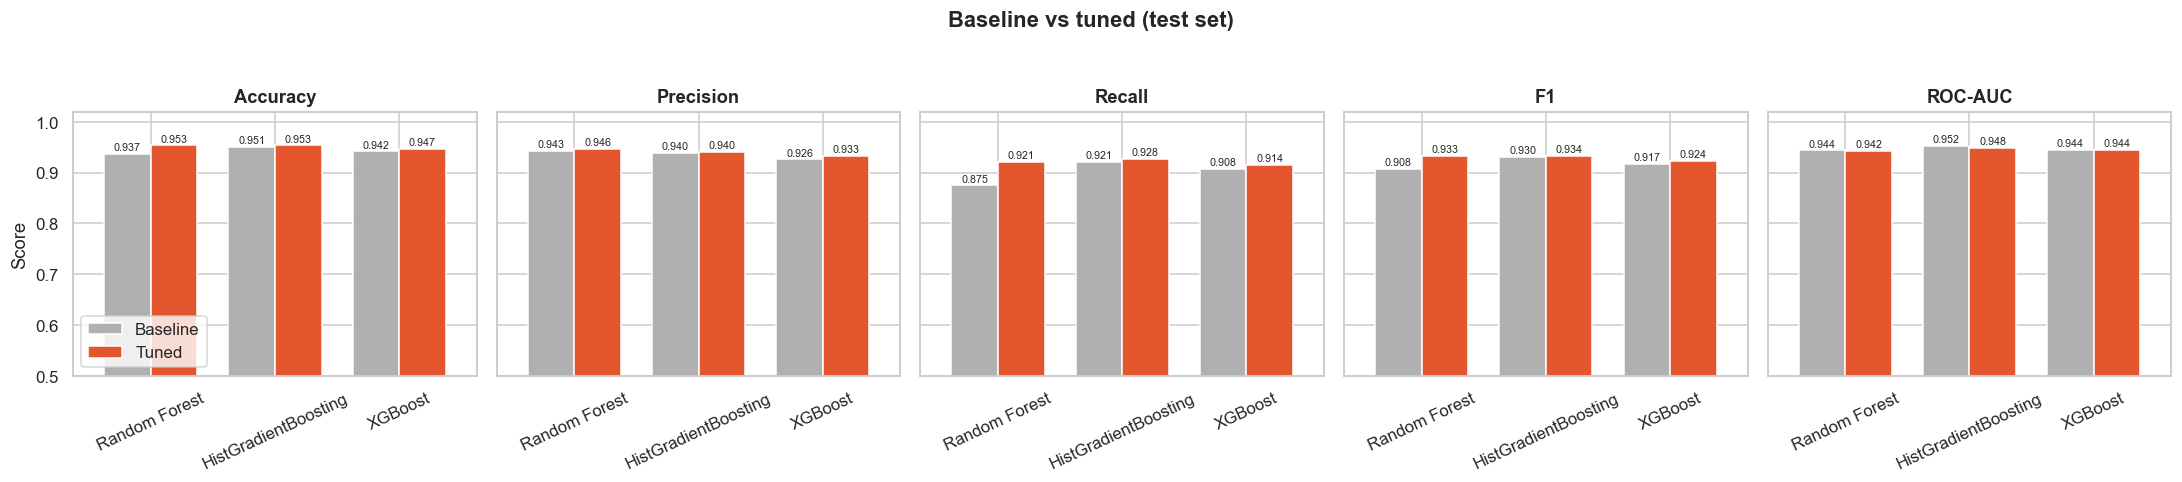

Change from tuning (tuned − baseline):


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,+0.0163,+0.0027,+0.0461,+0.0255,-0.0015
HistGradientBoosting,+0.0023,+0.0004,+0.0066,+0.0035,-0.0043
XGBoost,+0.0047,+0.0067,+0.0066,+0.0066,+0.0004


In [42]:
# (c) baseline vs tuned — did tuning actually help?
pairs = {"Random Forest": rf_base, "HistGradientBoosting": hgb_base, "XGBoost": xgb_base}
cmp_rows = []
for n, b in pairs.items():
    cmp_rows.append({**compute_metrics(b, X_test_s, y_test, n), "Version": "Baseline"})
    cmp_rows.append({**compute_metrics(tuned_models[n], X_test_s, y_test, n), "Version": "Tuned"})
cmp_df = pd.DataFrame(cmp_rows)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2), sharey=True)
for ax, met in zip(axes, ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]):
    piv = cmp_df.pivot(index="Model", columns="Version", values=met)[["Baseline", "Tuned"]].loc[list(pairs)]
    piv.plot(kind="bar", ax=ax, color=["#B0B0B0", "#E4572E"], width=.75, legend=False)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1)
    ax.set_title(met); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25); ax.set_ylim(0.5, 1.02)
axes[0].set_ylabel("Score"); axes[0].legend(loc="lower left")
plt.suptitle("Baseline vs tuned (test set)", fontweight="bold", y=1.04); plt.tight_layout(); plt.show()

delta = (cmp_df[cmp_df.Version == "Tuned"].set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
         - cmp_df[cmp_df.Version == "Baseline"].set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]])
print("Change from tuning (tuned − baseline):")
display(delta.style.format("{:+.4f}").background_gradient(cmap="RdYlGn", axis=None, vmin=-.05, vmax=.05))

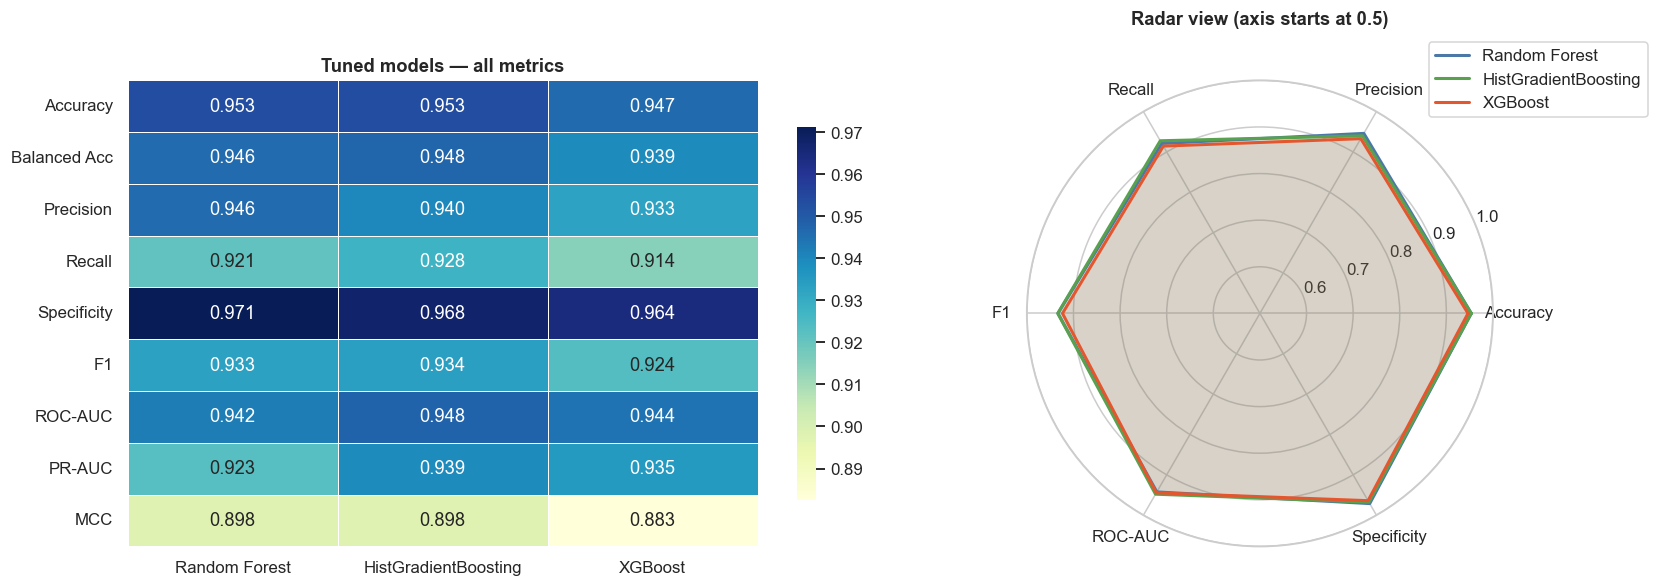

In [43]:
# (d) heatmap + radar overview
fig = plt.figure(figsize=(16, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
sns.heatmap(tuned_df[metric_cols].T, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"shrink": .8}, ax=ax1, linewidths=.5)
ax1.set_title("Tuned models — all metrics"); ax1.set_xlabel(""); ax1.tick_params(axis="x", rotation=0)

ax2 = fig.add_subplot(1, 2, 2, polar=True)
rad = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Specificity"]
ang = np.linspace(0, 2 * np.pi, len(rad), endpoint=False).tolist(); ang += ang[:1]
for n in tuned_df.index:
    v = tuned_df.loc[n, rad].values.astype(float).tolist(); v += v[:1]
    ax2.plot(ang, v, lw=2, color=colors[n], label=n); ax2.fill(ang, v, alpha=.12, color=colors[n])
ax2.set_xticks(ang[:-1]); ax2.set_xticklabels(rad); ax2.set_ylim(0.5, 1.0); ax2.set_title("Radar view (axis starts at 0.5)", y=1.1)
ax2.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.tight_layout(); plt.show()

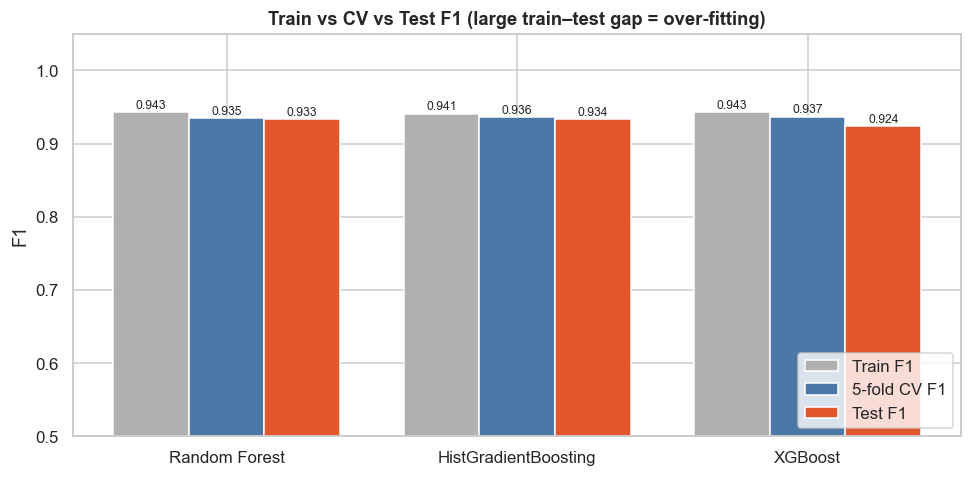

In [44]:
# (e) stability: is the test score consistent with cross-validation? (over-fitting check)
fig, ax = plt.subplots(figsize=(9, 4.5))
xx = np.arange(len(tuned_df)); w = .26
ax.bar(xx - w, tuned_df["Train F1"], w, label="Train F1", color="#B0B0B0")
ax.bar(xx, tuned_df["CV F1"], w, label="5-fold CV F1", color="#4C78A8")
ax.bar(xx + w, tuned_df["F1"], w, label="Test F1", color="#E4572E")
for i, n in enumerate(tuned_df.index):
    for off, c in zip([-w, 0, w], ["Train F1", "CV F1", "F1"]):
        ax.text(i + off, tuned_df.loc[n, c] + .005, f"{tuned_df.loc[n, c]:.3f}", ha="center", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(tuned_df.index); ax.set_ylim(0.5, 1.05); ax.set_ylabel("F1")
ax.set_title("Train vs CV vs Test F1 (large train–test gap = over-fitting)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

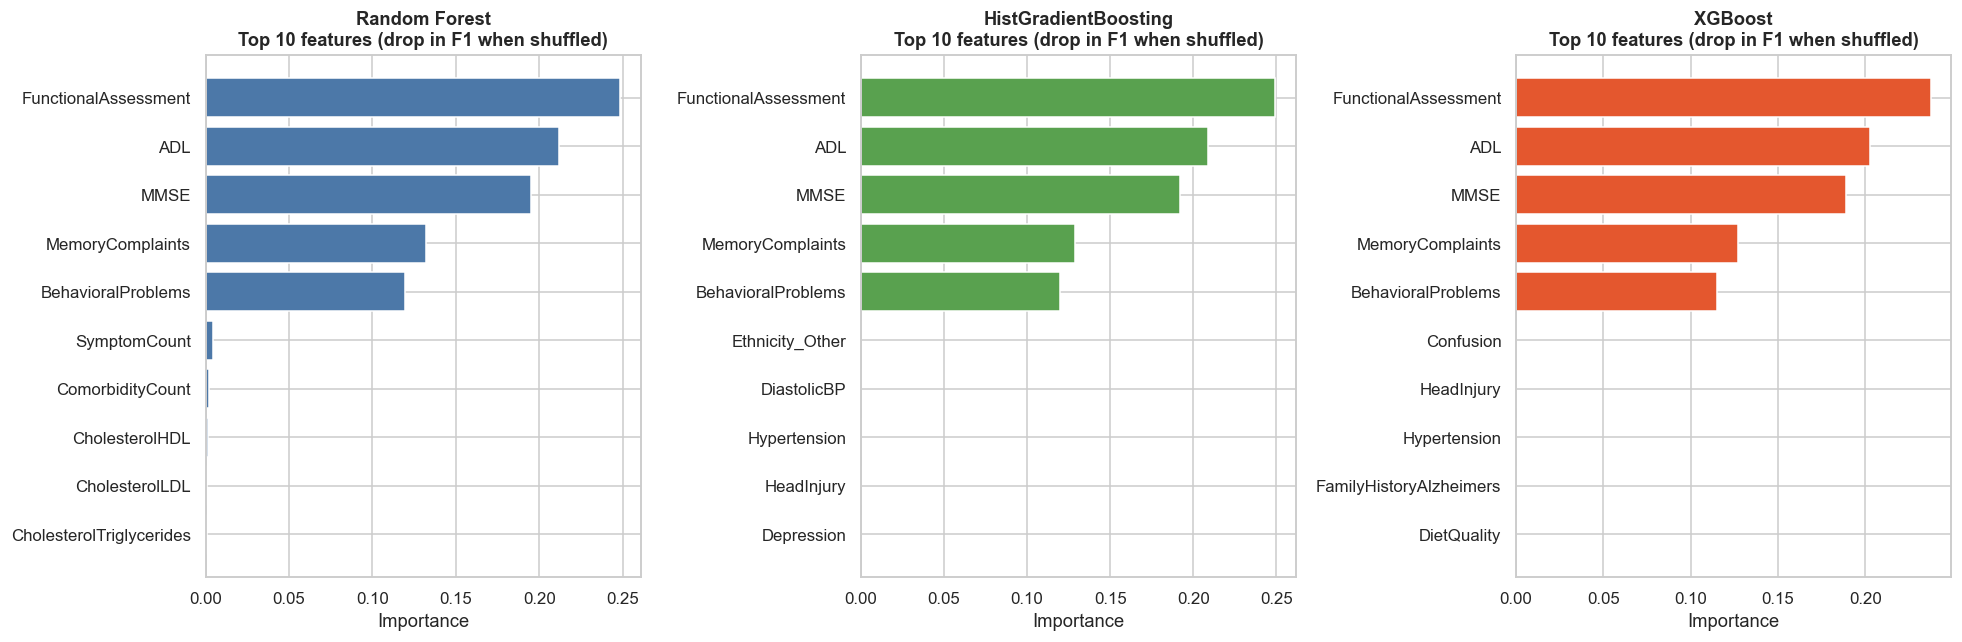

In [45]:
# (f) top features per tuned model (permutation importance on the test set - model-agnostic, so the 3 models are comparable)
from sklearn.inspection import permutation_importance
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (n, m) in zip(axes, tuned_models.items()):
    pi = permutation_importance(m, X_test_s, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=X_test_s.columns).sort_values().tail(10)
    ax.barh(imp.index, imp.values, color=colors[n]); ax.set_title(f"{n}\nTop 10 features (drop in F1 when shuffled)"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 15. Best model
Selection rule: highest **test F1** (the headline metric for this imbalanced problem), with **ROC-AUC** as the tie-breaker. The table also shows cross-validated F1 and the train–test gap so that a model that merely got lucky on one split, or one that over-fits, is easy to spot.

In [46]:
rank = tuned_df.sort_values(["F1", "ROC-AUC"], ascending=False)
best_name = rank.index[0]
best_model = tuned_models[best_name]

# rank of each model on every metric (1 = best)
rank_table = tuned_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "MCC"]].rank(ascending=False, method="min").astype(int)
rank_table["Avg rank"] = rank_table.mean(axis=1)
display(rank_table.sort_values("Avg rank").style.background_gradient(cmap="YlGn_r", subset=["Avg rank"]))

b = tuned_df.loc[best_name]
print("=" * 62)
print(f"  BEST MODEL : {best_name}")
print("=" * 62)
print(f"  Accuracy    {b['Accuracy']:.4f}   | Precision {b['Precision']:.4f}")
print(f"  Recall      {b['Recall']:.4f}   | Specificity {b['Specificity']:.4f}")
print(f"  F1          {b['F1']:.4f}   | ROC-AUC {b['ROC-AUC']:.4f}   | MCC {b['MCC']:.4f}")
print(f"  CV F1 (5-fold, train) {b['CV F1']:.4f}   | Train-Test F1 gap {b['Train–Test F1 gap']:.4f}")
print(f"  Confusion matrix: TN={int(b['TN'])}  FP={int(b['FP'])}  FN={int(b['FN'])}  TP={int(b['TP'])}")
print("\n  Best hyper-parameters:")
for k, v in searches[best_name].best_params_.items():
    print(f"    {k:20s} = {v}")

runner = rank.index[1]
print(f"\n  Margin over runner-up ({runner}): F1 {b['F1'] - tuned_df.loc[runner, 'F1']:+.4f}, ROC-AUC {b['ROC-AUC'] - tuned_df.loc[runner, 'ROC-AUC']:+.4f}")
if abs(b["F1"] - tuned_df.loc[runner, "F1"]) < 0.01:
    print("  NOTE: the margin is under 1 F1 point on ~430 test patients, i.e. within noise - treat the top models as practically equivalent.")

,Accuracy,Precision,Recall,F1,ROC-AUC,MCC,Avg rank
Model,,,,,,,
HistGradientBoosting,1,2,1,1,1,1,1.166667
Random Forest,1,1,2,2,3,2,1.833333
XGBoost,3,3,3,3,2,3,2.833333


  BEST MODEL : HistGradientBoosting
  Accuracy    0.9535   | Precision 0.9400
  Recall      0.9276   | Specificity 0.9676
  F1          0.9338   | ROC-AUC 0.9480   | MCC 0.8980
  CV F1 (5-fold, train) 0.9365   | Train-Test F1 gap 0.0070
  Confusion matrix: TN=269  FP=9  FN=11  TP=141

  Best hyper-parameters:
    min_samples_leaf     = 40
    max_leaf_nodes       = 8
    max_iter             = 500
    max_depth            = None
    learning_rate        = 0.01
    l2_regularization    = 1.0
    class_weight         = None

  Margin over runner-up (Random Forest): F1 +0.0004, ROC-AUC +0.0056
  NOTE: the margin is under 1 F1 point on ~430 test patients, i.e. within noise - treat the top models as practically equivalent.


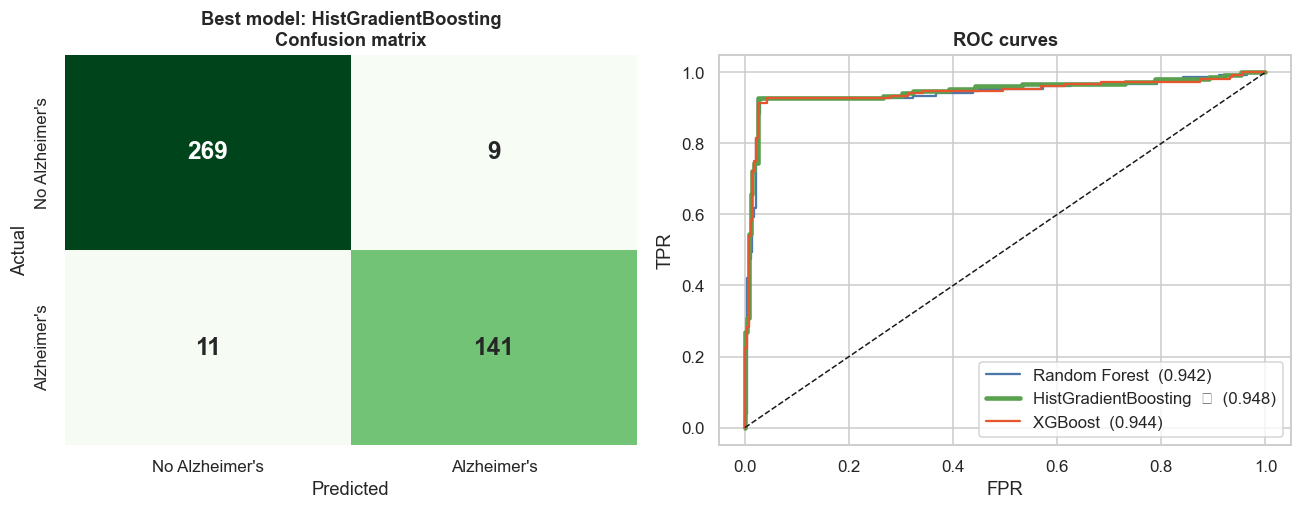

Saved best model, comparison tables and best hyper-parameters to: C:\Users\Ankit\ADproject\cleaned_output


In [47]:
# Final visual: best model's confusion matrix + ROC, with the other two for context
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
cm = confusion_matrix(y_test, best_model.predict(X_test_s))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], annot_kws={"size": 16, "weight": "bold"})
axes[0].set_title(f"Best model: {best_name}\nConfusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
for n, m in tuned_models.items():
    p = get_proba(m, X_test_s); fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, lw=3 if n == best_name else 1.5, color=colors[n], label=f"{n}{'  ★' if n == best_name else ''}  ({roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].legend(loc="lower right"); axes[1].set_title("ROC curves"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()

# Save artefacts
import joblib
joblib.dump(best_model, os.path.join(OUTPUT_DIR, f"best_model_{best_name.replace(' ', '_')}.joblib"))
tuned_df.to_csv(os.path.join(OUTPUT_DIR, "tuned_model_comparison.csv"))
baseline_df.to_csv(os.path.join(OUTPUT_DIR, "baseline_model_comparison.csv"), index=False)
best_params_df.to_csv(os.path.join(OUTPUT_DIR, "best_hyperparameters.csv"))
print("Saved best model, comparison tables and best hyper-parameters to:", os.path.abspath(OUTPUT_DIR))

### Notes & caveats
- **Test set used once for model selection.** Hyper-parameters were chosen purely by cross-validation on the training data; the test set was then used to compare the three tuned models and pick the winner. For a fully unbiased performance estimate you would hold out a further validation split or use nested CV.
- **Small test set.** With ~430 test patients, differences of roughly 1 percentage point between models are within sampling noise.
- **Pre-scaled data.** Continuous features were standardised in Section 5 (fit on train only). This has no effect on tree-based models (RF, HistGB, XGBoost) and is required for SVM / KNN / Logistic Regression, so one shared dataset serves all baselines.
- **Reproducibility.** Everything is seeded with `RANDOM_STATE = 42`; results can still vary slightly across scikit-learn / XGBoost versions.
- **Research use only.** These are academic predictive models, not clinical diagnostic tools.

In [48]:

# ==========================================
# FINAL STEP: SAVE BEST MODEL AS JOBLIB FILE
# ==========================================

import joblib
import os

# 1. Select the tuned HistGradientBoosting model
best_model = tuned_models["HistGradientBoosting"]

# 2. Prepare model package
model_package = {
    "model": best_model,
    "scaler": scaler,
    "feature_columns": X_train.columns.tolist(),
    "scale_columns": scale_cols,
    "target_column": TARGET,
    "class_names": CLASS_NAMES
}

# 3. Save complete model package
model_path = os.path.join(
    OUTPUT_DIR,
    "HistGradientBoosting_Alzheimers.joblib"
)

joblib.dump(model_package, model_path)

# 4. Save model separately as well
separate_model_path = os.path.join(
    OUTPUT_DIR,
    "HistGradientBoosting_Model_Only.joblib"
)

joblib.dump(best_model, separate_model_path)

# 5. Confirm successful saving
print("MODEL SAVED SUCCESSFULLY!")
print("--------------------------------------")
print("Best Model:", "HistGradientBoosting")
print("Complete Model Package:", model_path)
print("Model Only:", separate_model_path)
print("--------------------------------------")

# 6. Verify that the saved model can be loaded
loaded_package = joblib.load(model_path)

print("Model Verification:", type(loaded_package["model"]).__name__)
print("Number of Features:", len(loaded_package["feature_columns"]))
print("Model loaded successfully!")


MODEL SAVED SUCCESSFULLY!
--------------------------------------
Best Model: HistGradientBoosting
Complete Model Package: cleaned_output\HistGradientBoosting_Alzheimers.joblib
Model Only: cleaned_output\HistGradientBoosting_Model_Only.joblib
--------------------------------------
Model Verification: HistGradientBoostingClassifier
Number of Features: 39
Model loaded successfully!
